[![Mở bằng Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Puuffiiii/261-ML-Assignment-G3/blob/main/notebooks/ML_Tabular_Final.ipynb)

# Pipeline Machine Learning hoàn chỉnh — HR Analytics

**Mục tiêu:** chạy trọn vẹn EDA, làm sạch, tiền xử lý, tạo đặc trưng, huấn luyện/tuning hai mô hình truyền thống (**Logistic Regression**, **Random Forest**), hai mô hình học sâu (**ResNet**, **TabM**), đánh giá khóa kín và xuất artefact suy luận.

**Nguồn dữ liệu gốc:** [Kaggle — HR Analytics: Job Change of Data Scientists](https://www.kaggle.com/datasets/arashnic/hr-analytics-job-change-of-data-scientists). Bản CSV đi kèm repository công khai được kiểm tra SHA-256 để notebook chạy không cần Kaggle credential và không mount Google Drive.

Notebook tuân thủ ba nguyên tắc:

1. Chia dữ liệu trước khi học mọi thống kê để tránh rò rỉ dữ liệu.
2. Chỉ `fit` imputation, encoding, scaling và PCA trên tập train.
3. Giữ riêng validation cho chọn mô hình/early stopping và test cho đánh giá cuối cùng; các audit test cuối chỉ mang tính mô tả, không được dùng để chọn lại mô hình.


## 0. Luồng xử lý và khả năng tái lập

`Dữ liệu thô → kiểm tra chất lượng → EDA → split 70/15/15 → imputation → encoding → feature engineering → scaling/PCA → tuning validation → khóa cấu hình/ngưỡng → test một lần → xuất artefact`

- Seed cố định: `42`.
- Đầu ra chính: các mảng `.npy`, tên đặc trưng, metadata, chỉ số split và preprocessor đã fit trong `features/`.
- Các biểu đồ EDA được lưu tại `reports/figures/`.

In [1]:
import os
import sys
import json
import platform
import warnings
import hashlib
import subprocess
import urllib.request
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib-ml-assignment")

# Tự nhận diện môi trường Local/Colab.
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/Puuffiiii/261-ML-Assignment-G3.git"
    REPO_NAME = "261-ML-Assignment-G3"
    RELEASE_REF = "main"  # đổi thành tag submission sau khi chốt thông tin nhóm
    if not Path(REPO_NAME).exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", RELEASE_REF, REPO_URL], check=True)
    PROJECT_ROOT = Path(REPO_NAME).resolve()
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_ROOT / "requirements.txt")],
        check=True,
    )
else:
    current = Path.cwd().resolve()
    PROJECT_ROOT = current.parent if (current.parent / "modules").exists() else current

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import torch
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.utils.class_weight import compute_class_weight

from modules.eda_viz import (
    check_city_cdi_relationship,
    get_missing_stats,
    plot_correlation_matrix,
    plot_high_cardinality_feature,
    plot_missing_values,
    plot_missingness_vs_target,
    plot_nominal_feature,
    plot_numerical_feature,
    plot_ordinal_feature,
    plot_target_distribution,
)
from modules.deep_learning import (
    DeepTabularPreprocessor,
    evaluate_deep_models_on_test,
    load_deep_model_artifact,
    plot_deep_model_results,
    predict_deep_from_raw_dataframe,
    run_deep_validation_experiments,
    save_deep_model_artifacts,
    select_best_deep_candidates,
)
from modules.modeling import (
    feature_importance_table,
    load_experiment_config,
    plot_model_comparison,
    predict_from_raw_dataframe,
    refit_and_evaluate_on_test,
    run_validation_experiments,
    save_model_artifacts,
    select_best_candidates,
)
from modules.preprocessing import (
    ENGINEERED_FEATURES,
    NOMINAL_COLS,
    ORDINAL_MAPPINGS,
    TabularPreprocessor,
    load_processed_features,
    load_raw_dataset,
    save_processed_features,
    split_train_validation_test,
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
DATA_PATH = PROJECT_ROOT / "data" / "aug_train.csv"
FEATURES_DIR = PROJECT_ROOT / "features"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODEL_CONFIG_PATH = PROJECT_ROOT / "configs" / "model_experiments.json"
DEEP_CONFIG_PATH = PROJECT_ROOT / "configs" / "deep_learning_experiments.json"
DATA_SHA256 = "8b78da3482032500df40d5359c36ba4a59e28ccd6fc272b050dcf6dee37f114c"
DATA_PUBLIC_URL = "https://raw.githubusercontent.com/Puuffiiii/261-ML-Assignment-G3/main/data/aug_train.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_PUBLIC_URL, DATA_PATH)
actual_data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if actual_data_sha256 != DATA_SHA256:
    raise RuntimeError(
        f"Dataset checksum mismatch: expected {DATA_SHA256}, got {actual_data_sha256}"
    )
FEATURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", context="notebook")
print(f"Project root: {PROJECT_ROOT}")
print(f"Python {platform.python_version()} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Project root: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3
Python 3.14.7 | pandas 3.1.0 | scikit-learn 1.9.1


## 1. Nạp dữ liệu và kiểm tra chất lượng

Tập dữ liệu gồm hồ sơ ứng viên ngành khoa học dữ liệu. Biến đích `target` nhận `1` nếu ứng viên muốn thay đổi công việc và `0` nếu không.

In [2]:
df_raw = load_raw_dataset(str(DATA_PATH))
print(f"Kích thước dữ liệu: {df_raw.shape[0]:,} dòng × {df_raw.shape[1]} cột")
display(df_raw.head())
display(df_raw.dtypes.rename("dtype").to_frame().T)

Kích thước dữ liệu: 19,158 dòng × 14 cột


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
dtype,int64,str,float64,str,str,str,str,str,str,str,str,str,int64,float64


In [3]:
quality_summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values(["missing_pct", "n_unique"], ascending=[False, False])

duplicate_rows = int(df_raw.duplicated().sum())
duplicate_ids = int(df_raw["enrollee_id"].duplicated().sum())
invalid_targets = int((~df_raw["target"].isin([0, 1])).sum())
print({
    "dòng_trùng_hoàn_toàn": duplicate_rows,
    "enrollee_id_trùng": duplicate_ids,
    "target_không_hợp_lệ": invalid_targets,
})
display(quality_summary)

assert duplicate_ids == 0
assert invalid_targets == 0

{'dòng_trùng_hoàn_toàn': 0, 'enrollee_id_trùng': 0, 'target_không_hợp_lệ': 0}


,dtype,missing_count,missing_pct,n_unique
company_type,str,6140,32.05,6
company_size,str,5938,30.99,8
gender,str,4508,23.53,3
major_discipline,str,2813,14.68,6
education_level,str,460,2.40,5
last_new_job,str,423,2.21,6
enrolled_university,str,386,2.01,3
experience,str,65,0.34,22
enrollee_id,int64,0,0.00,19158
training_hours,int64,0,0.00,241


## 2. Exploratory Data Analysis (EDA)

Phần này trả lời bốn câu hỏi: target mất cân bằng đến đâu, biến nào có tín hiệu dự báo, missingness có mang thông tin hay không, và cột nào nên loại bỏ trước mô hình hóa.

,count,pct
target,,
0.0,14381,75.07
1.0,4777,24.93


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group1_target_distribution.png


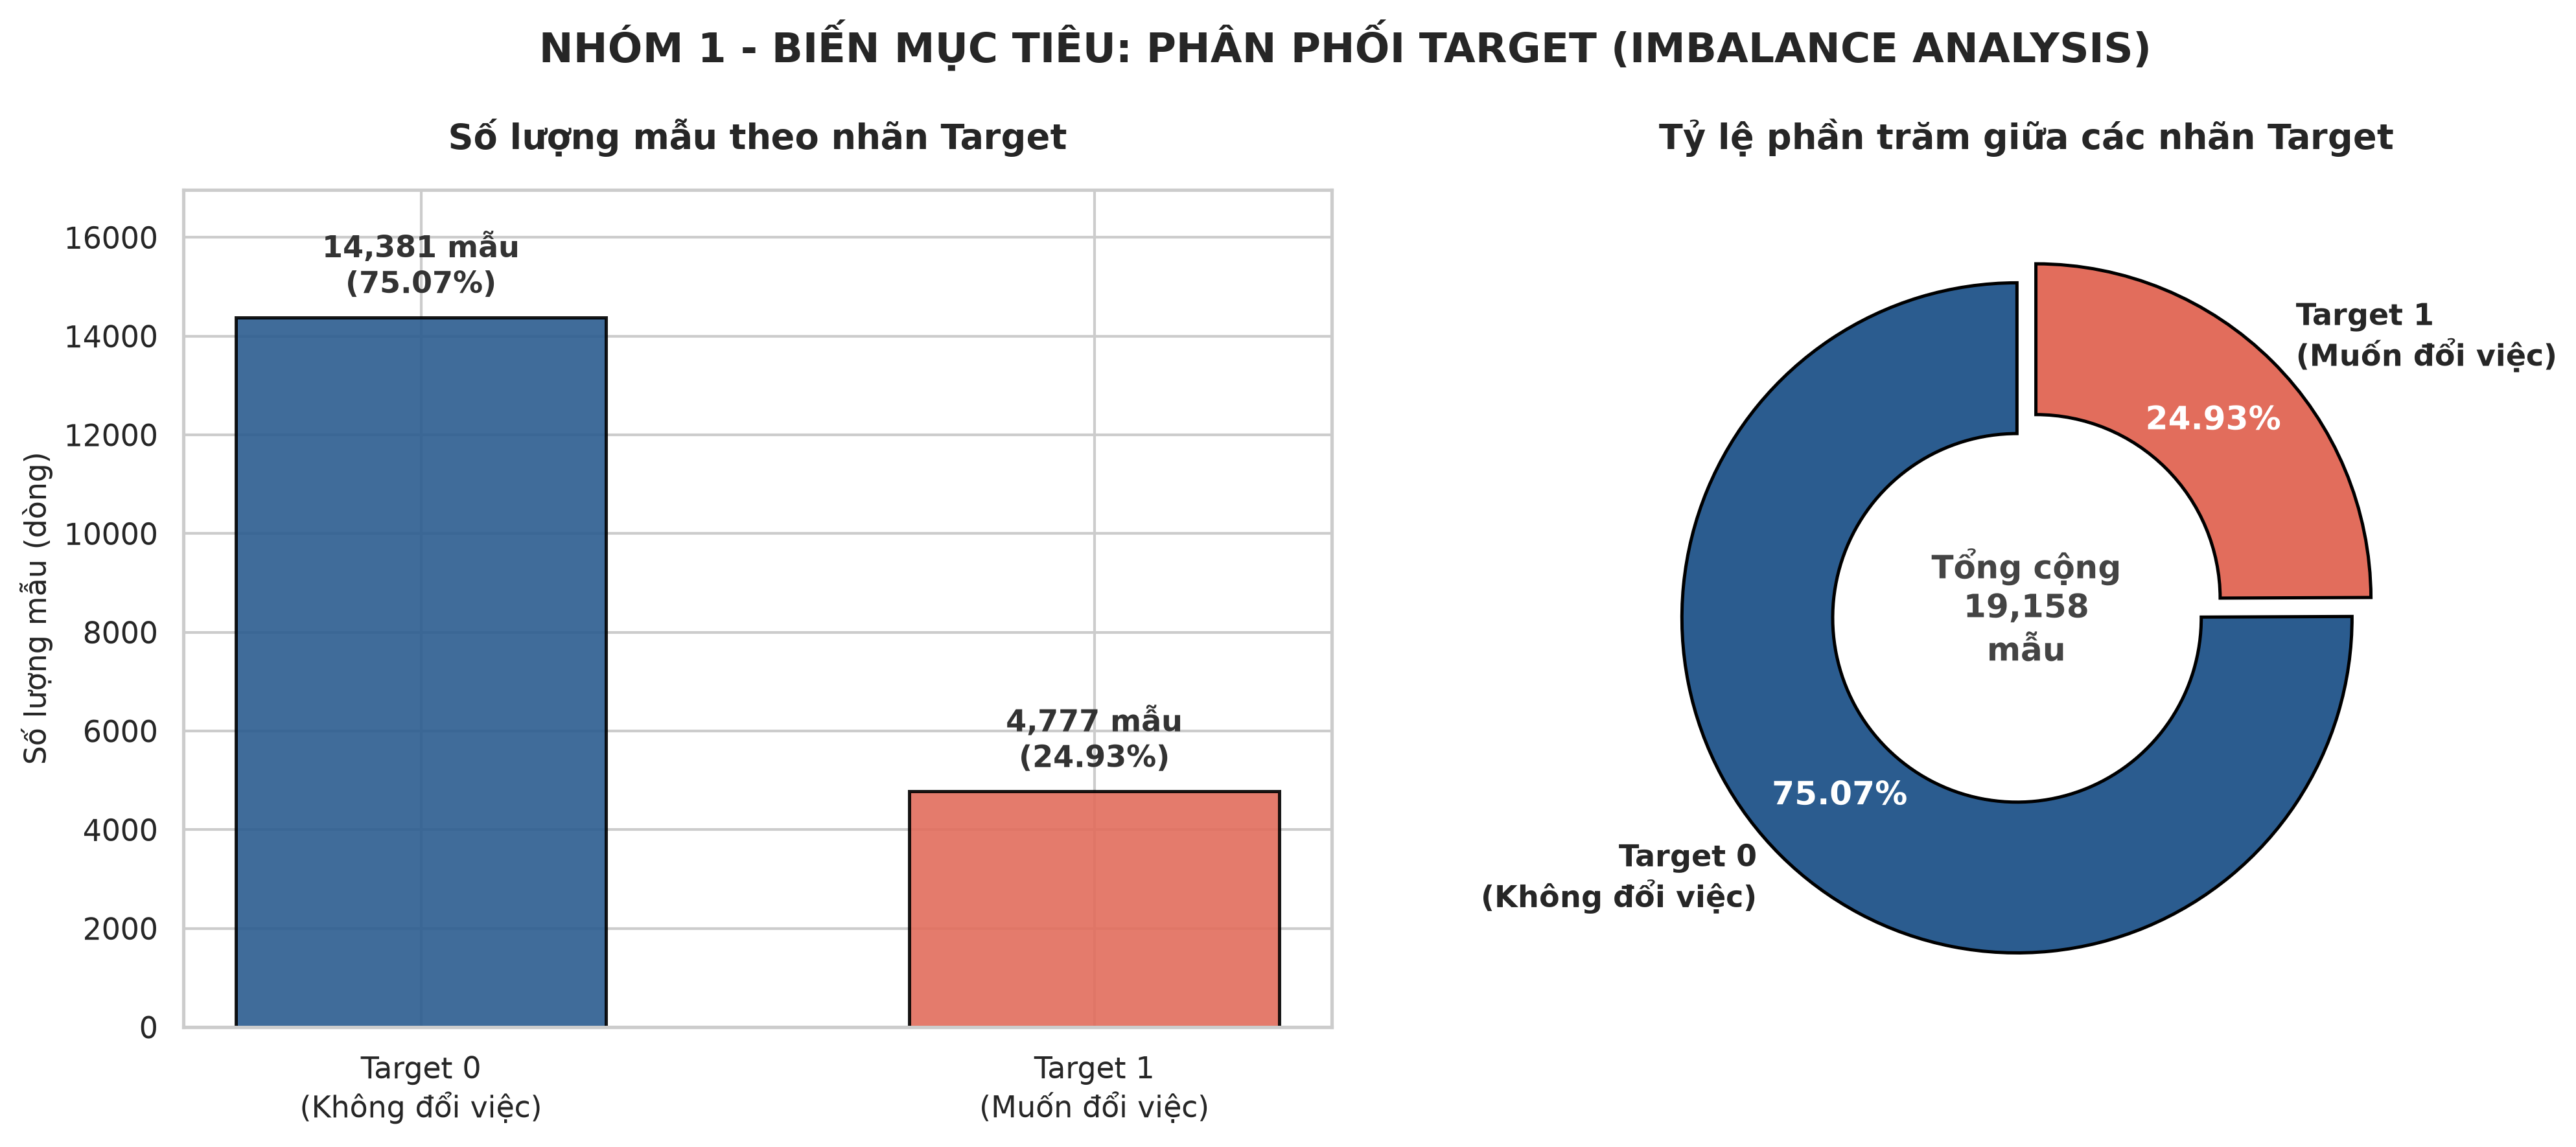

In [4]:
target_summary = df_raw["target"].value_counts().sort_index().to_frame("count")
target_summary["pct"] = (target_summary["count"] / len(df_raw) * 100).round(2)
display(target_summary)
plot_target_distribution(
    df_raw,
    save_path=str(FIGURES_DIR / "group1_target_distribution.png"),
    show=True,
)

,Kiểu dữ liệu,Số dòng khuyết,Tỷ lệ khuyết (%),Số giá trị duy nhất
company_type,str,6140,32.05,6
company_size,str,5938,30.99,8
gender,str,4508,23.53,3
major_discipline,str,2813,14.68,6
education_level,str,460,2.40,5
last_new_job,str,423,2.21,6
enrolled_university,str,386,2.01,3
experience,str,65,0.34,22


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group6_missing_values_bar.png


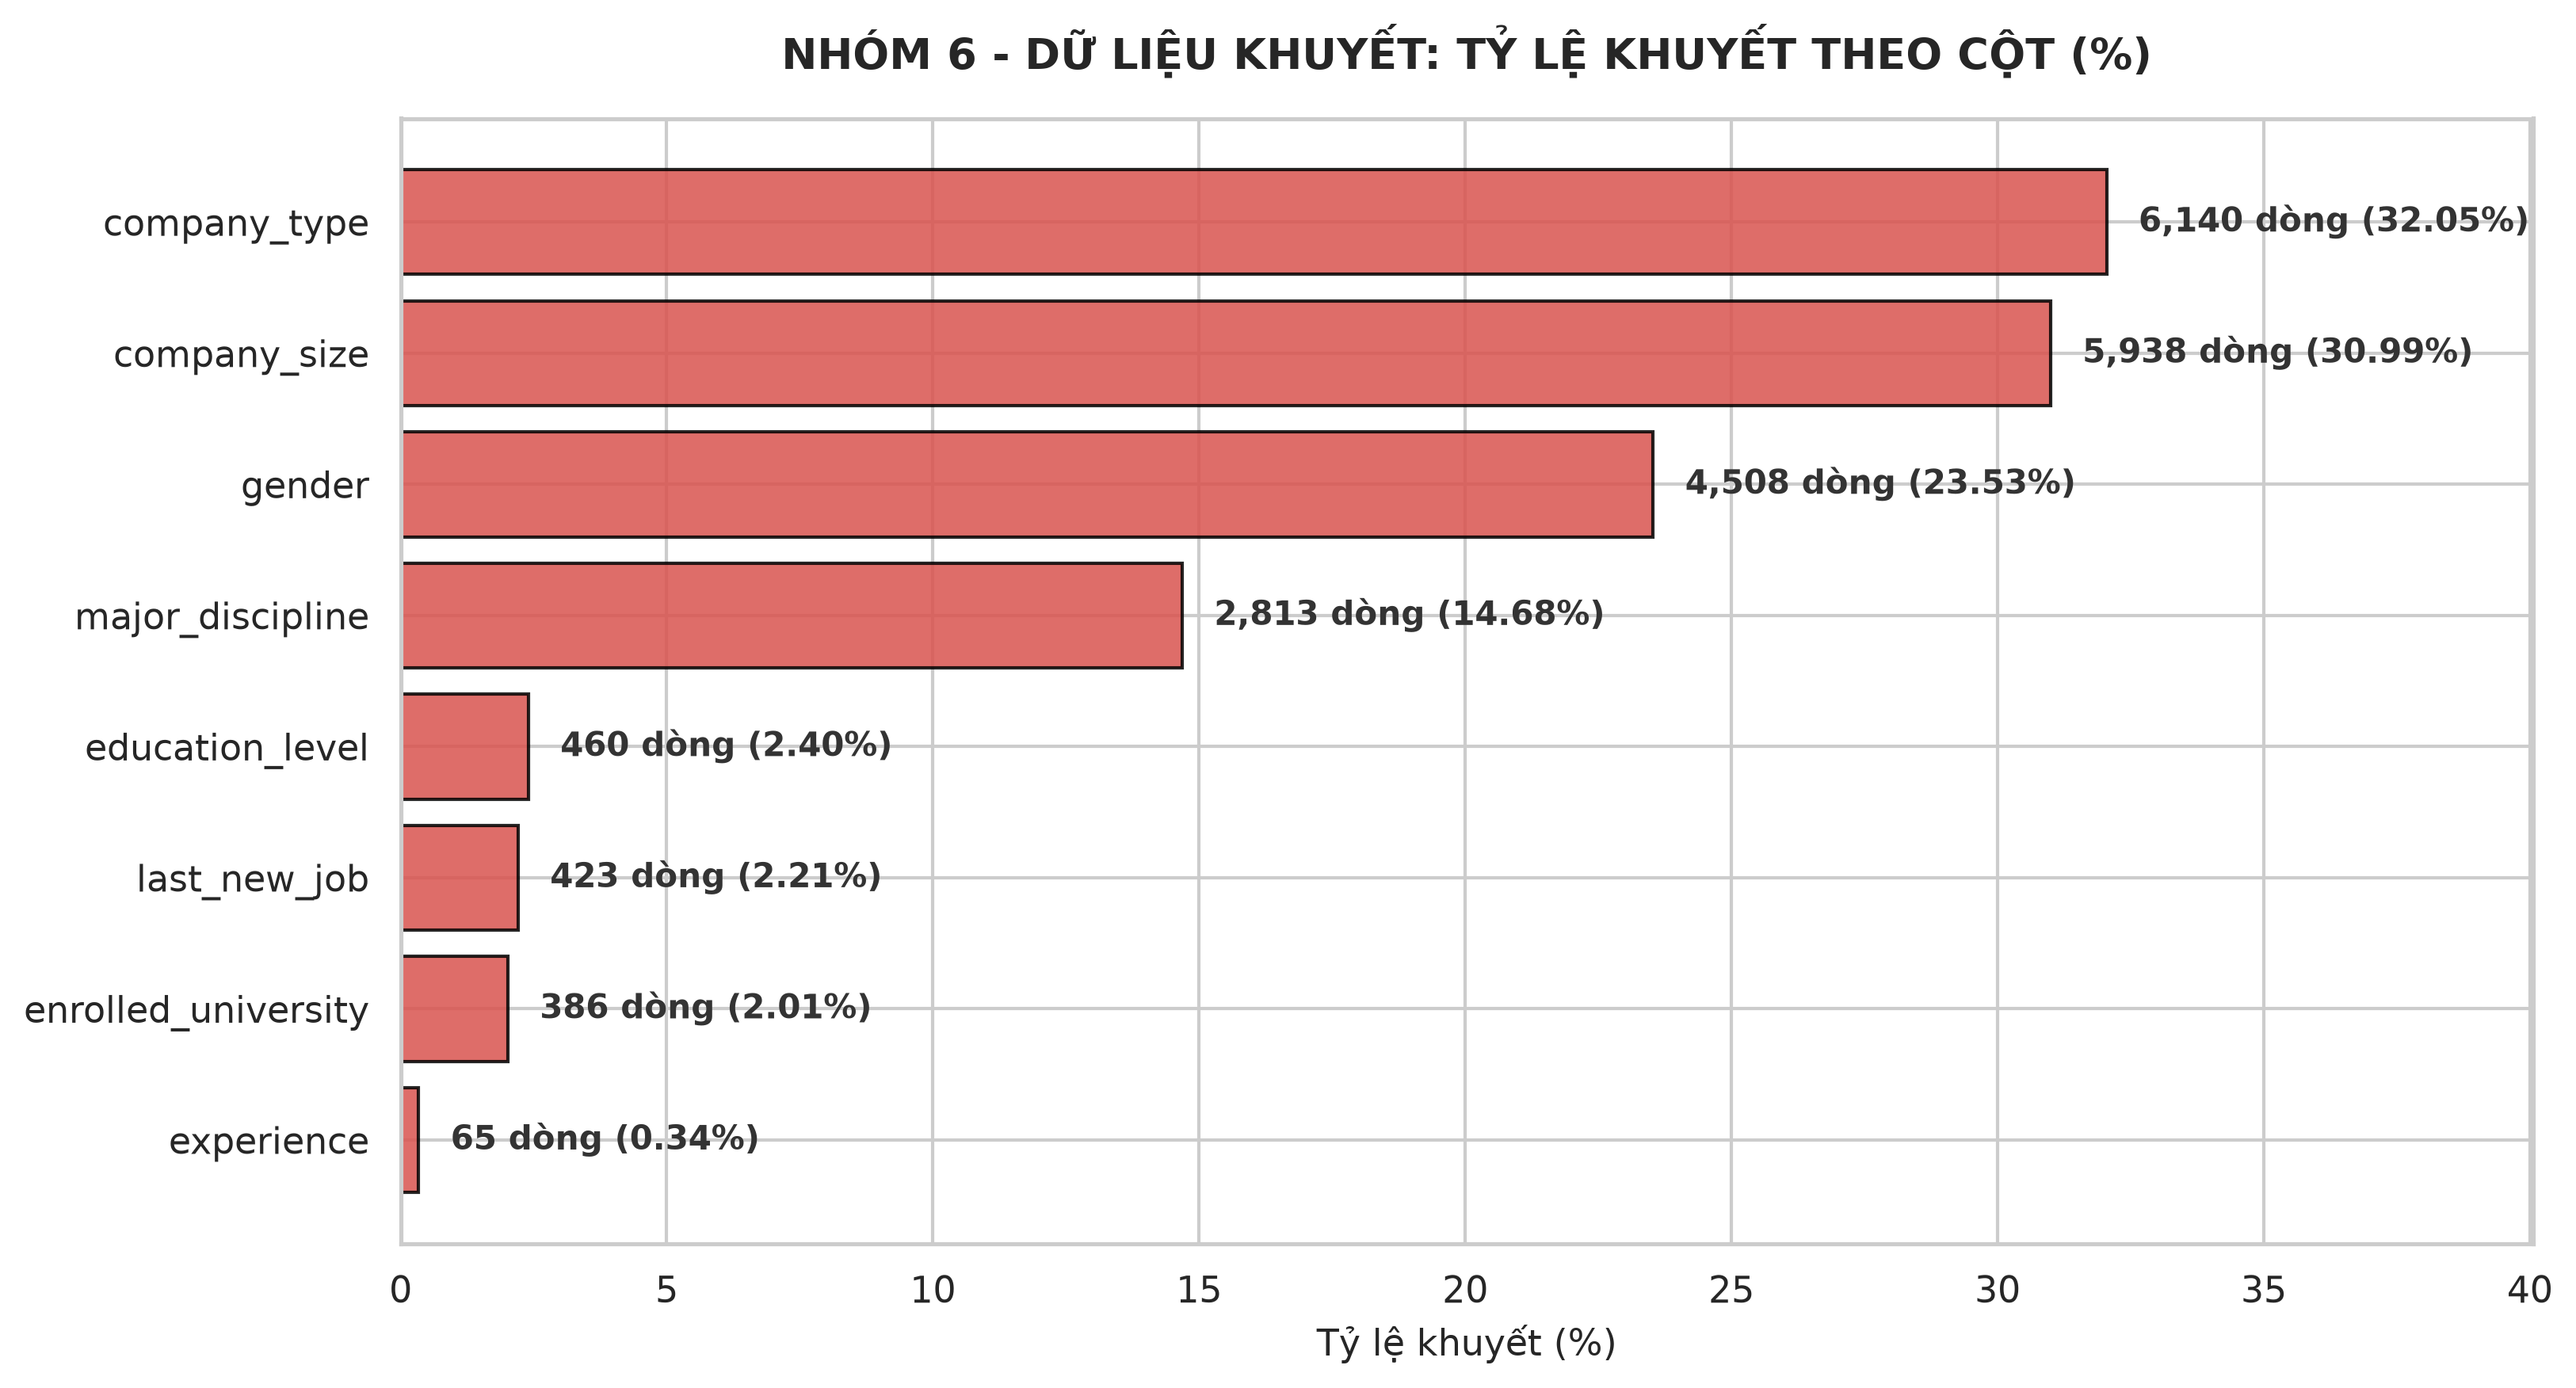

In [5]:
missing_stats = get_missing_stats(df_raw)
display(missing_stats[missing_stats["Số dòng khuyết"] > 0])
plot_missing_values(
    df_raw,
    save_path=str(FIGURES_DIR / "group6_missing_values_bar.png"),
    show=True,
)

city_development_index               training_hours               
                         mean median    std           mean median     std
target                                                                   
0.0                     0.853   0.91  0.105         66.114   48.0  60.939
1.0                     0.756   0.74  0.143         63.118   46.0  57.274

-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group2_num_city_development_index.png


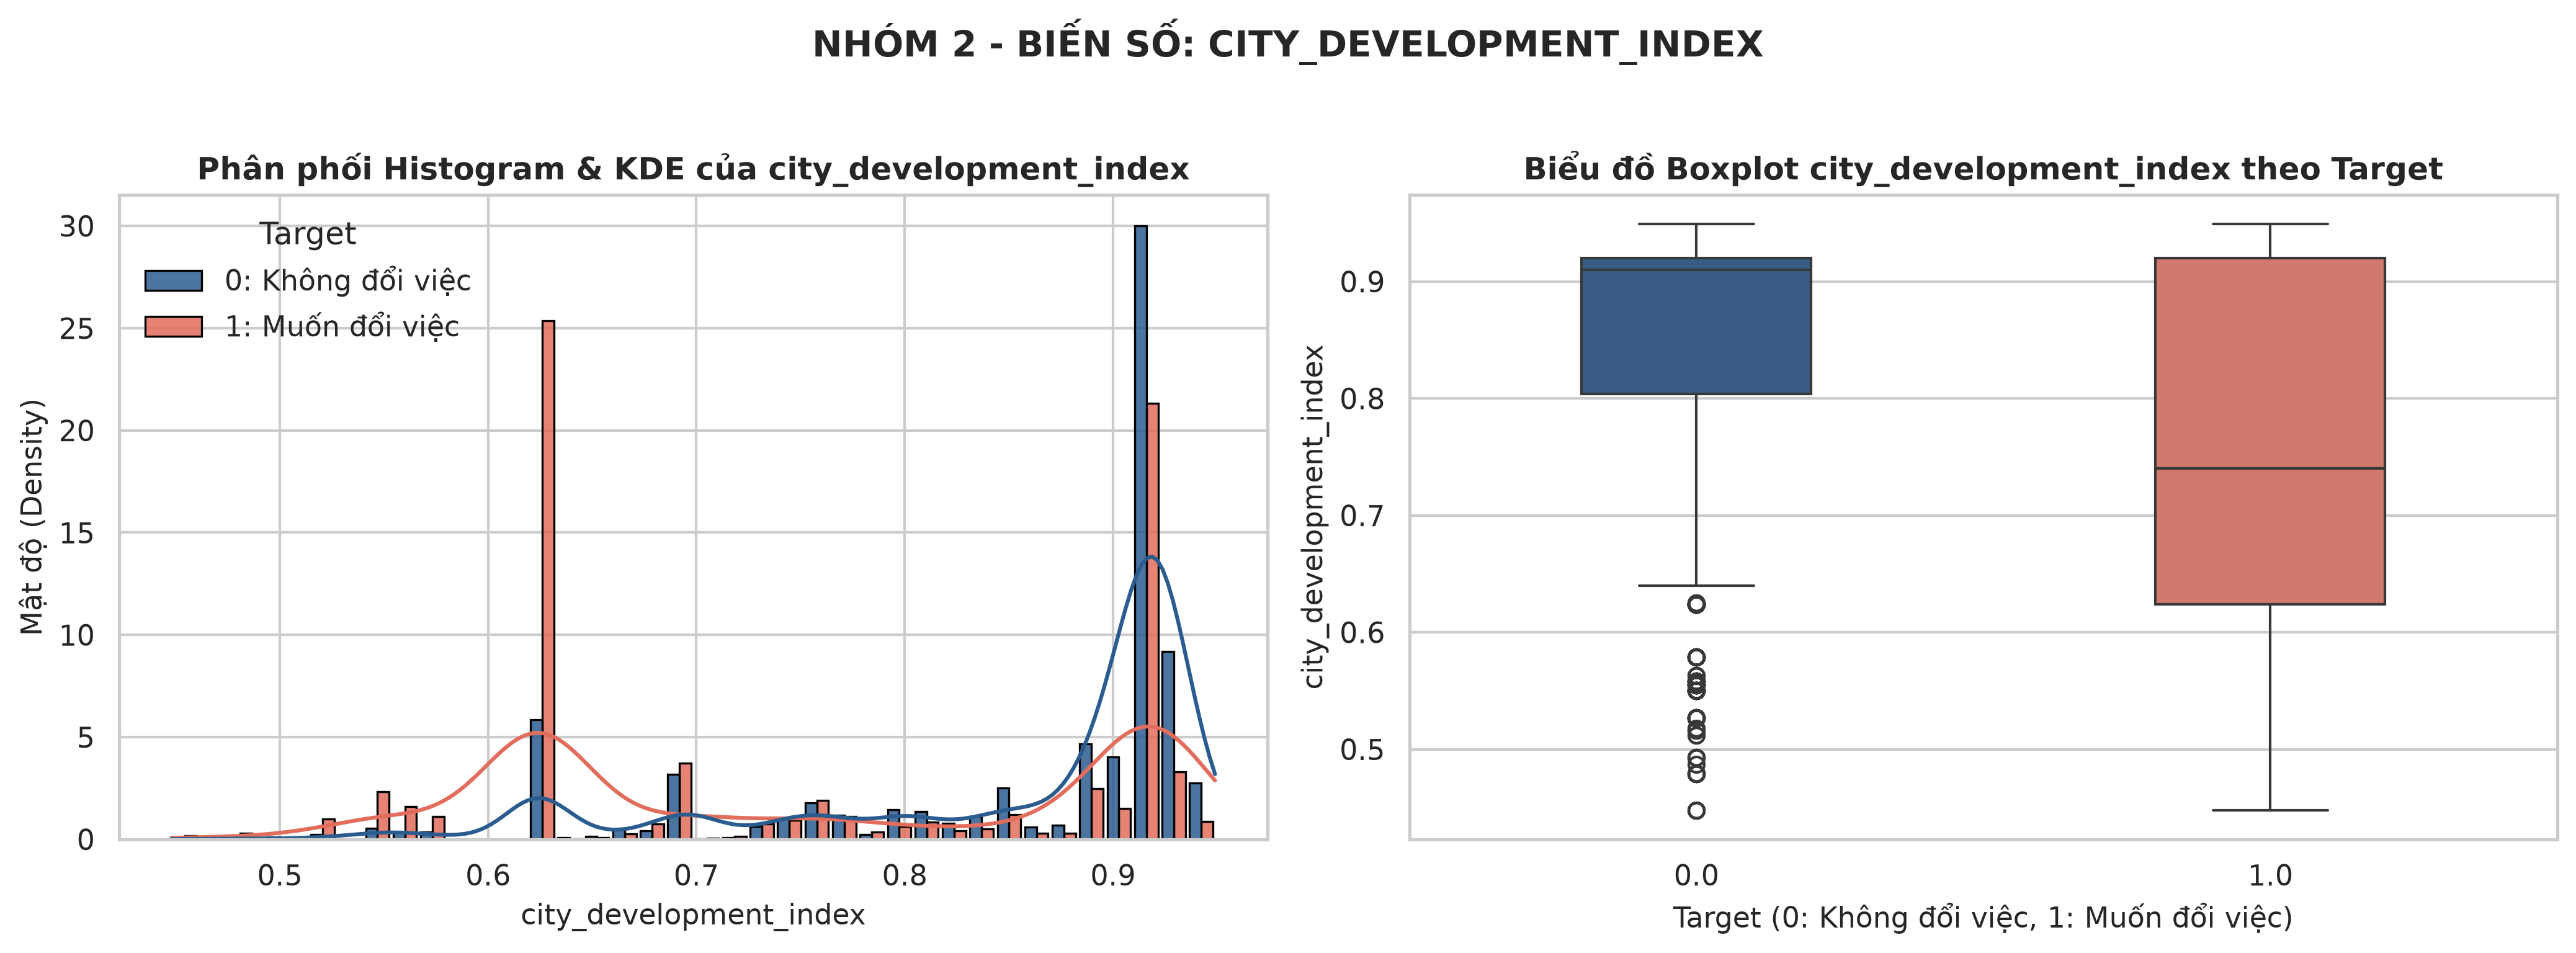

-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group2_num_training_hours.png


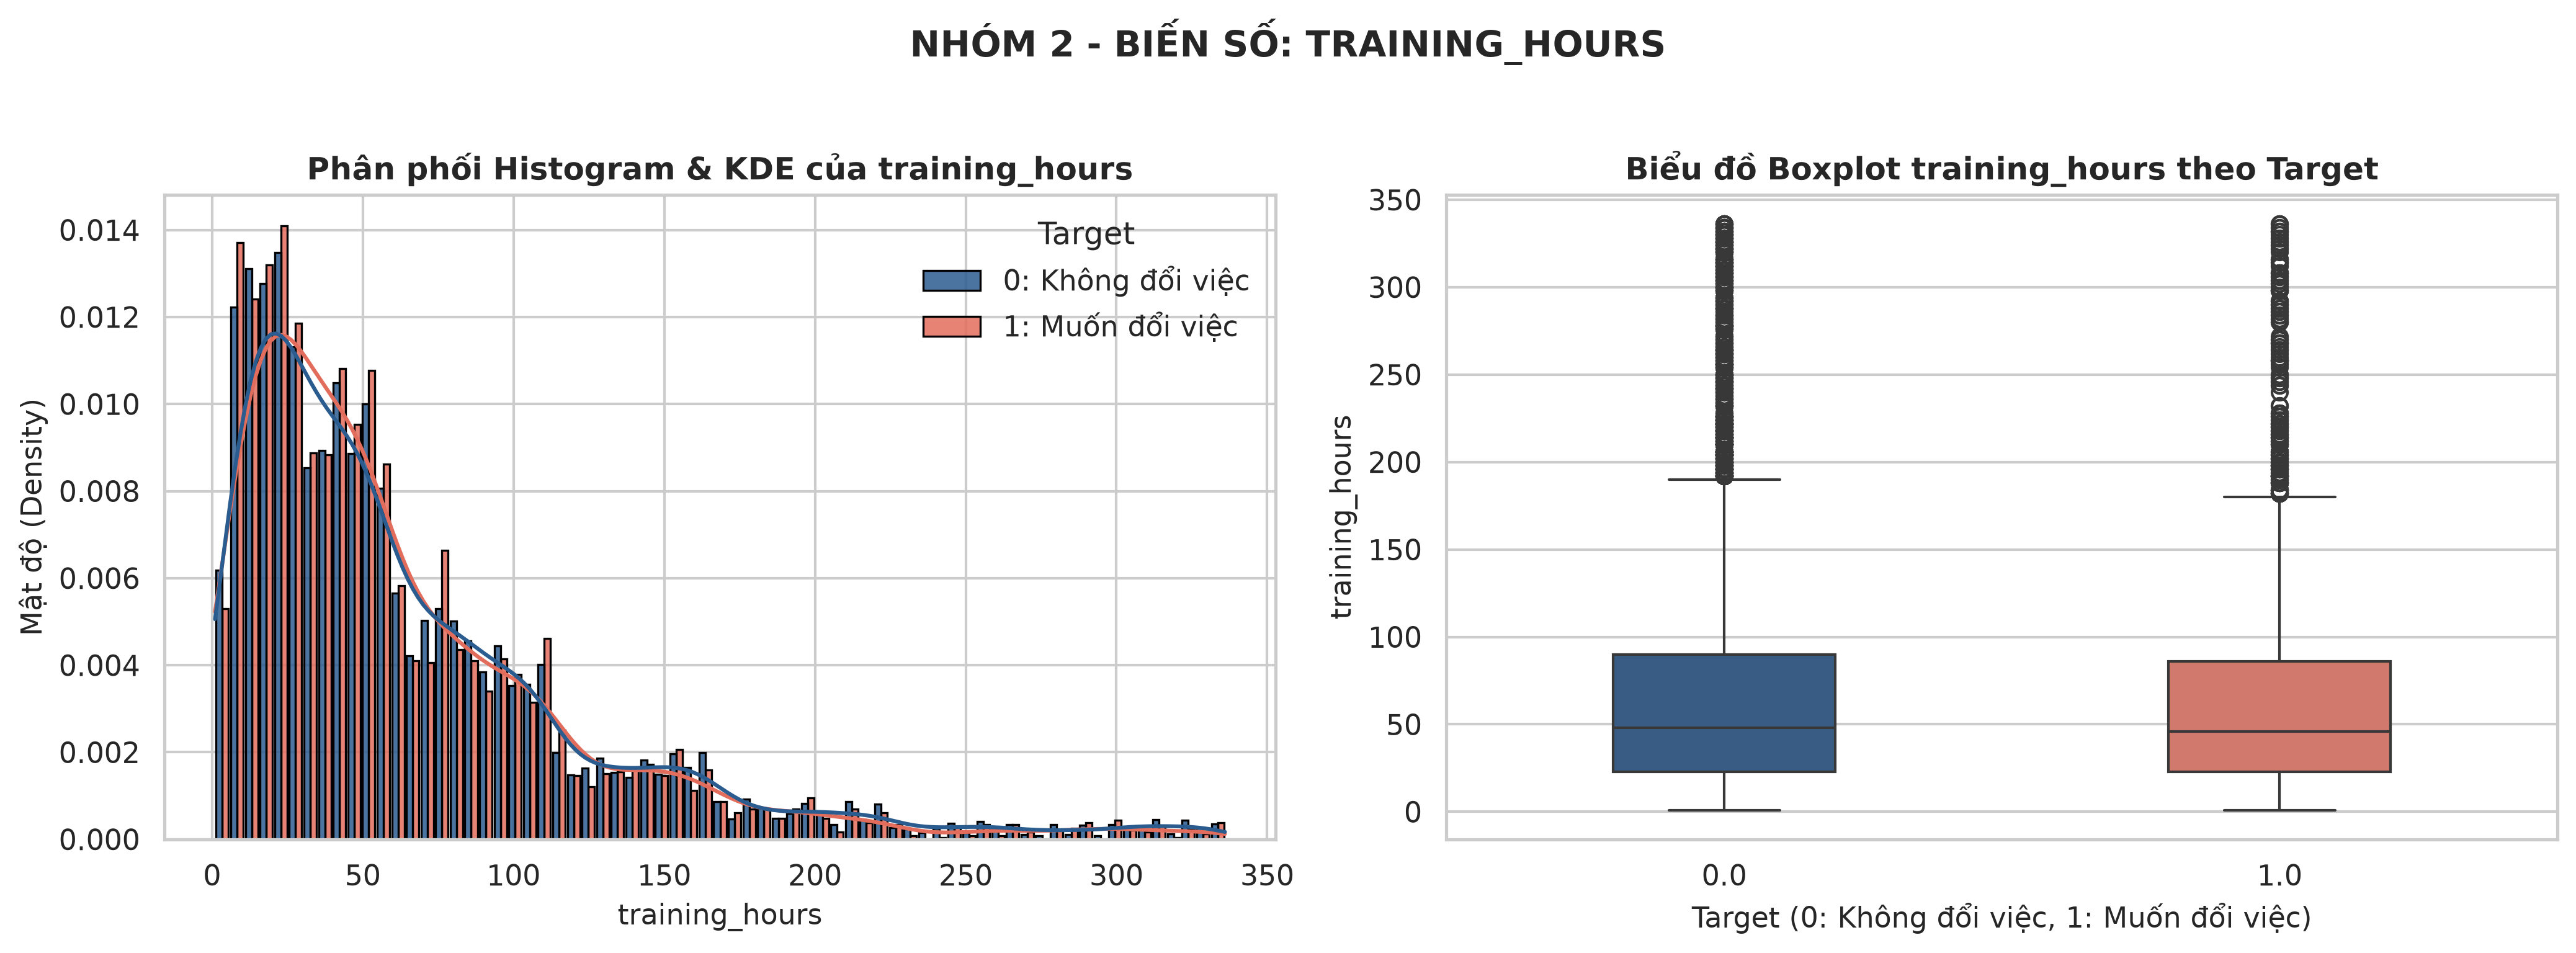

In [6]:
numerical_cols = ["city_development_index", "training_hours"]
display(df_raw.groupby("target")[numerical_cols].agg(["mean", "median", "std"]).round(3))

for col in numerical_cols:
    plot_numerical_feature(
        df_raw,
        col,
        save_path=str(FIGURES_DIR / f"group2_num_{col}.png"),
        show=True,
    )

In [7]:
# Bảng gọn: tỷ lệ target=1 theo từng nhóm của toàn bộ biến phân loại/thứ bậc.
categorical_cols = [
    "gender", "relevent_experience", "enrolled_university",
    "education_level", "major_discipline", "experience",
    "company_size", "company_type", "last_new_job",
]
category_rows = []
for col in categorical_cols:
    temp = df_raw[[col, "target"]].copy()
    temp[col] = temp[col].fillna("(Missing)")
    stats = temp.groupby(col, observed=False)["target"].agg(["size", "mean"]).reset_index()
    stats["feature"] = col
    stats["target_rate_pct"] = (stats["mean"] * 100).round(2)
    category_rows.append(stats.rename(columns={col: "category"})[[
        "feature", "category", "size", "target_rate_pct"
    ]])
category_target_rates = pd.concat(category_rows, ignore_index=True)
display(category_target_rates.sort_values(["feature", "target_rate_pct"], ascending=[True, False]))
category_target_rates.to_csv(REPORTS_DIR / "categorical_target_rates.csv", index=False)

,feature,category,size,target_rate_pct
46,company_size,(Missing),5938,40.59
47,company_size,10/49,1471,23.39
50,company_size,10000+,2019,19.07
53,company_size,5000-9999,563,18.12
51,company_size,50-99,3083,17.68
...,...,...,...,...
19,major_discipline,Humanities,669,21.08
17,major_discipline,Arts,253,20.95
16,major_discipline,(Missing),2813,19.52
5,relevent_experience,No relevent experience,5366,33.84


,Tổng số thành phố (unique cities),Số lượng CDI tối đa trên mỗi thành phố,Số lượng CDI tối thiểu trên mỗi thành phố,Quan hệ 1 - 1 (Toàn vẹn)
0,123,1,1,CÓ (100% Phù hợp)


Kết luận: city có 123 mức và ánh xạ 1-1 sang city_development_index; loại city giúp tránh one-hot dư thừa.


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group5_high_cardinality_city_top15.png


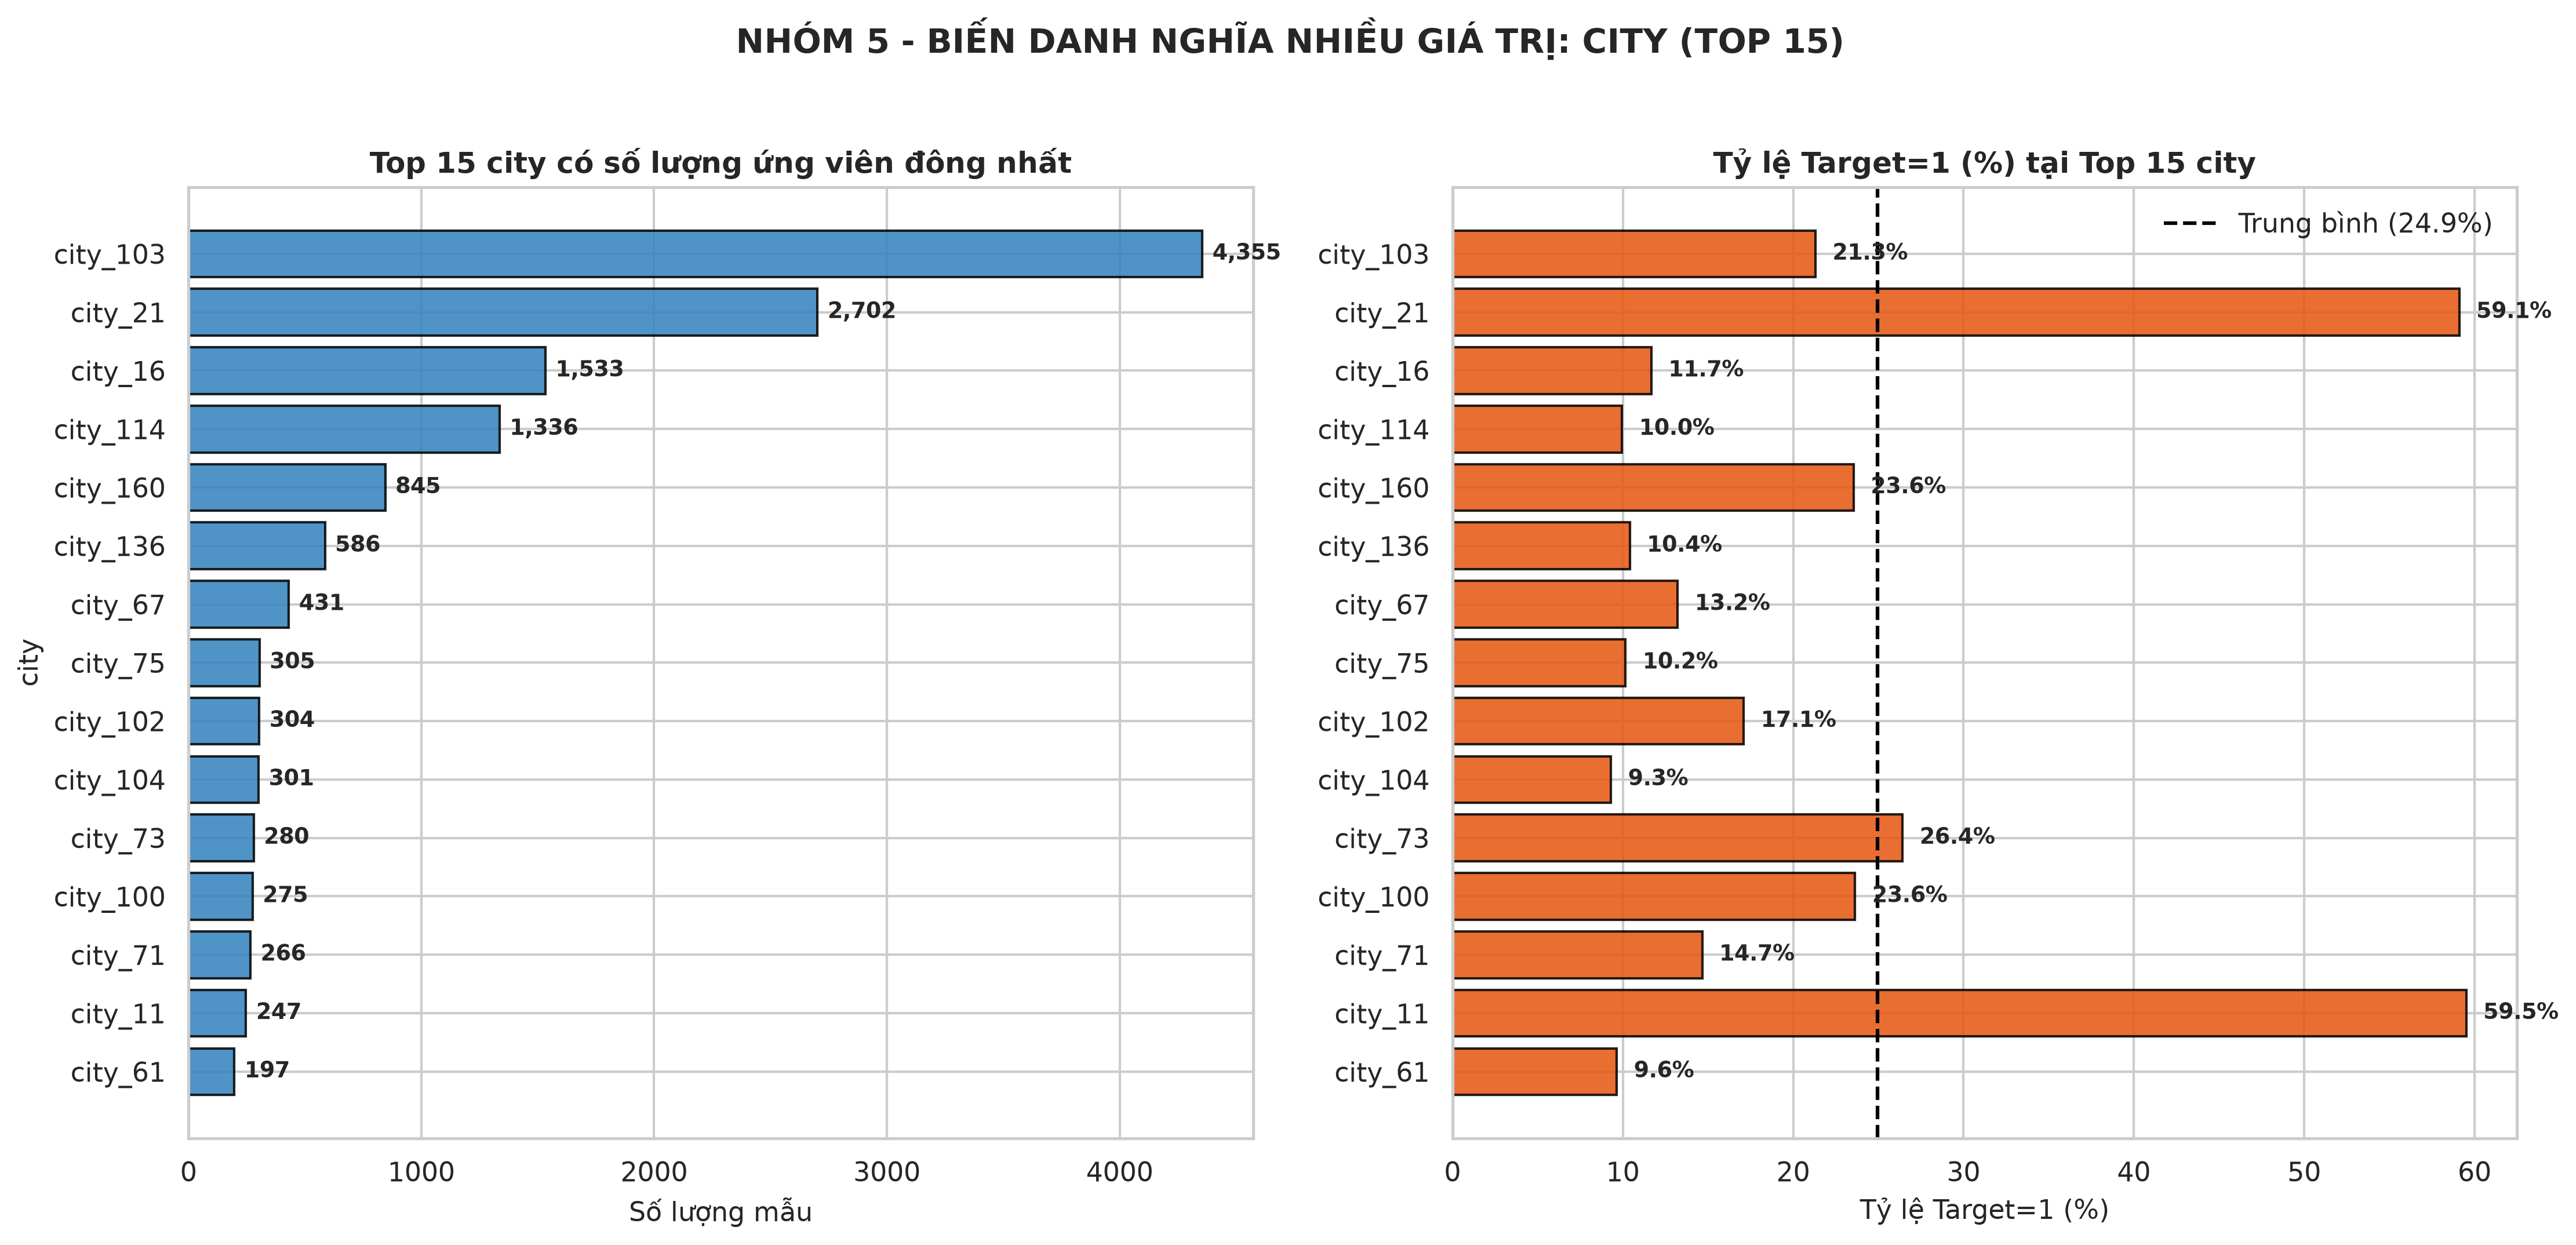

In [8]:
city_cdi_check = check_city_cdi_relationship(df_raw)
display(city_cdi_check)
print(
    "Kết luận: city có 123 mức và ánh xạ 1-1 sang city_development_index; "
    "loại city giúp tránh one-hot dư thừa."
)
plot_high_cardinality_feature(
    df_raw,
    col="city",
    top_n=15,
    save_path=str(FIGURES_DIR / "group5_high_cardinality_city_top15.png"),
    show=True,
)

,feature,target_rate_observed_pct,target_rate_missing_pct,difference_pp
5,company_size,17.90,40.59,22.68
6,company_type,18.38,38.83,20.45
7,last_new_job,24.68,36.41,11.73
4,experience,24.90,35.38,10.49
0,gender,23.13,30.81,7.69
1,enrolled_university,24.79,31.87,7.07
2,education_level,24.99,22.61,-2.38
3,major_discipline,25.87,19.52,-6.35


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group6_missingness_vs_target.png


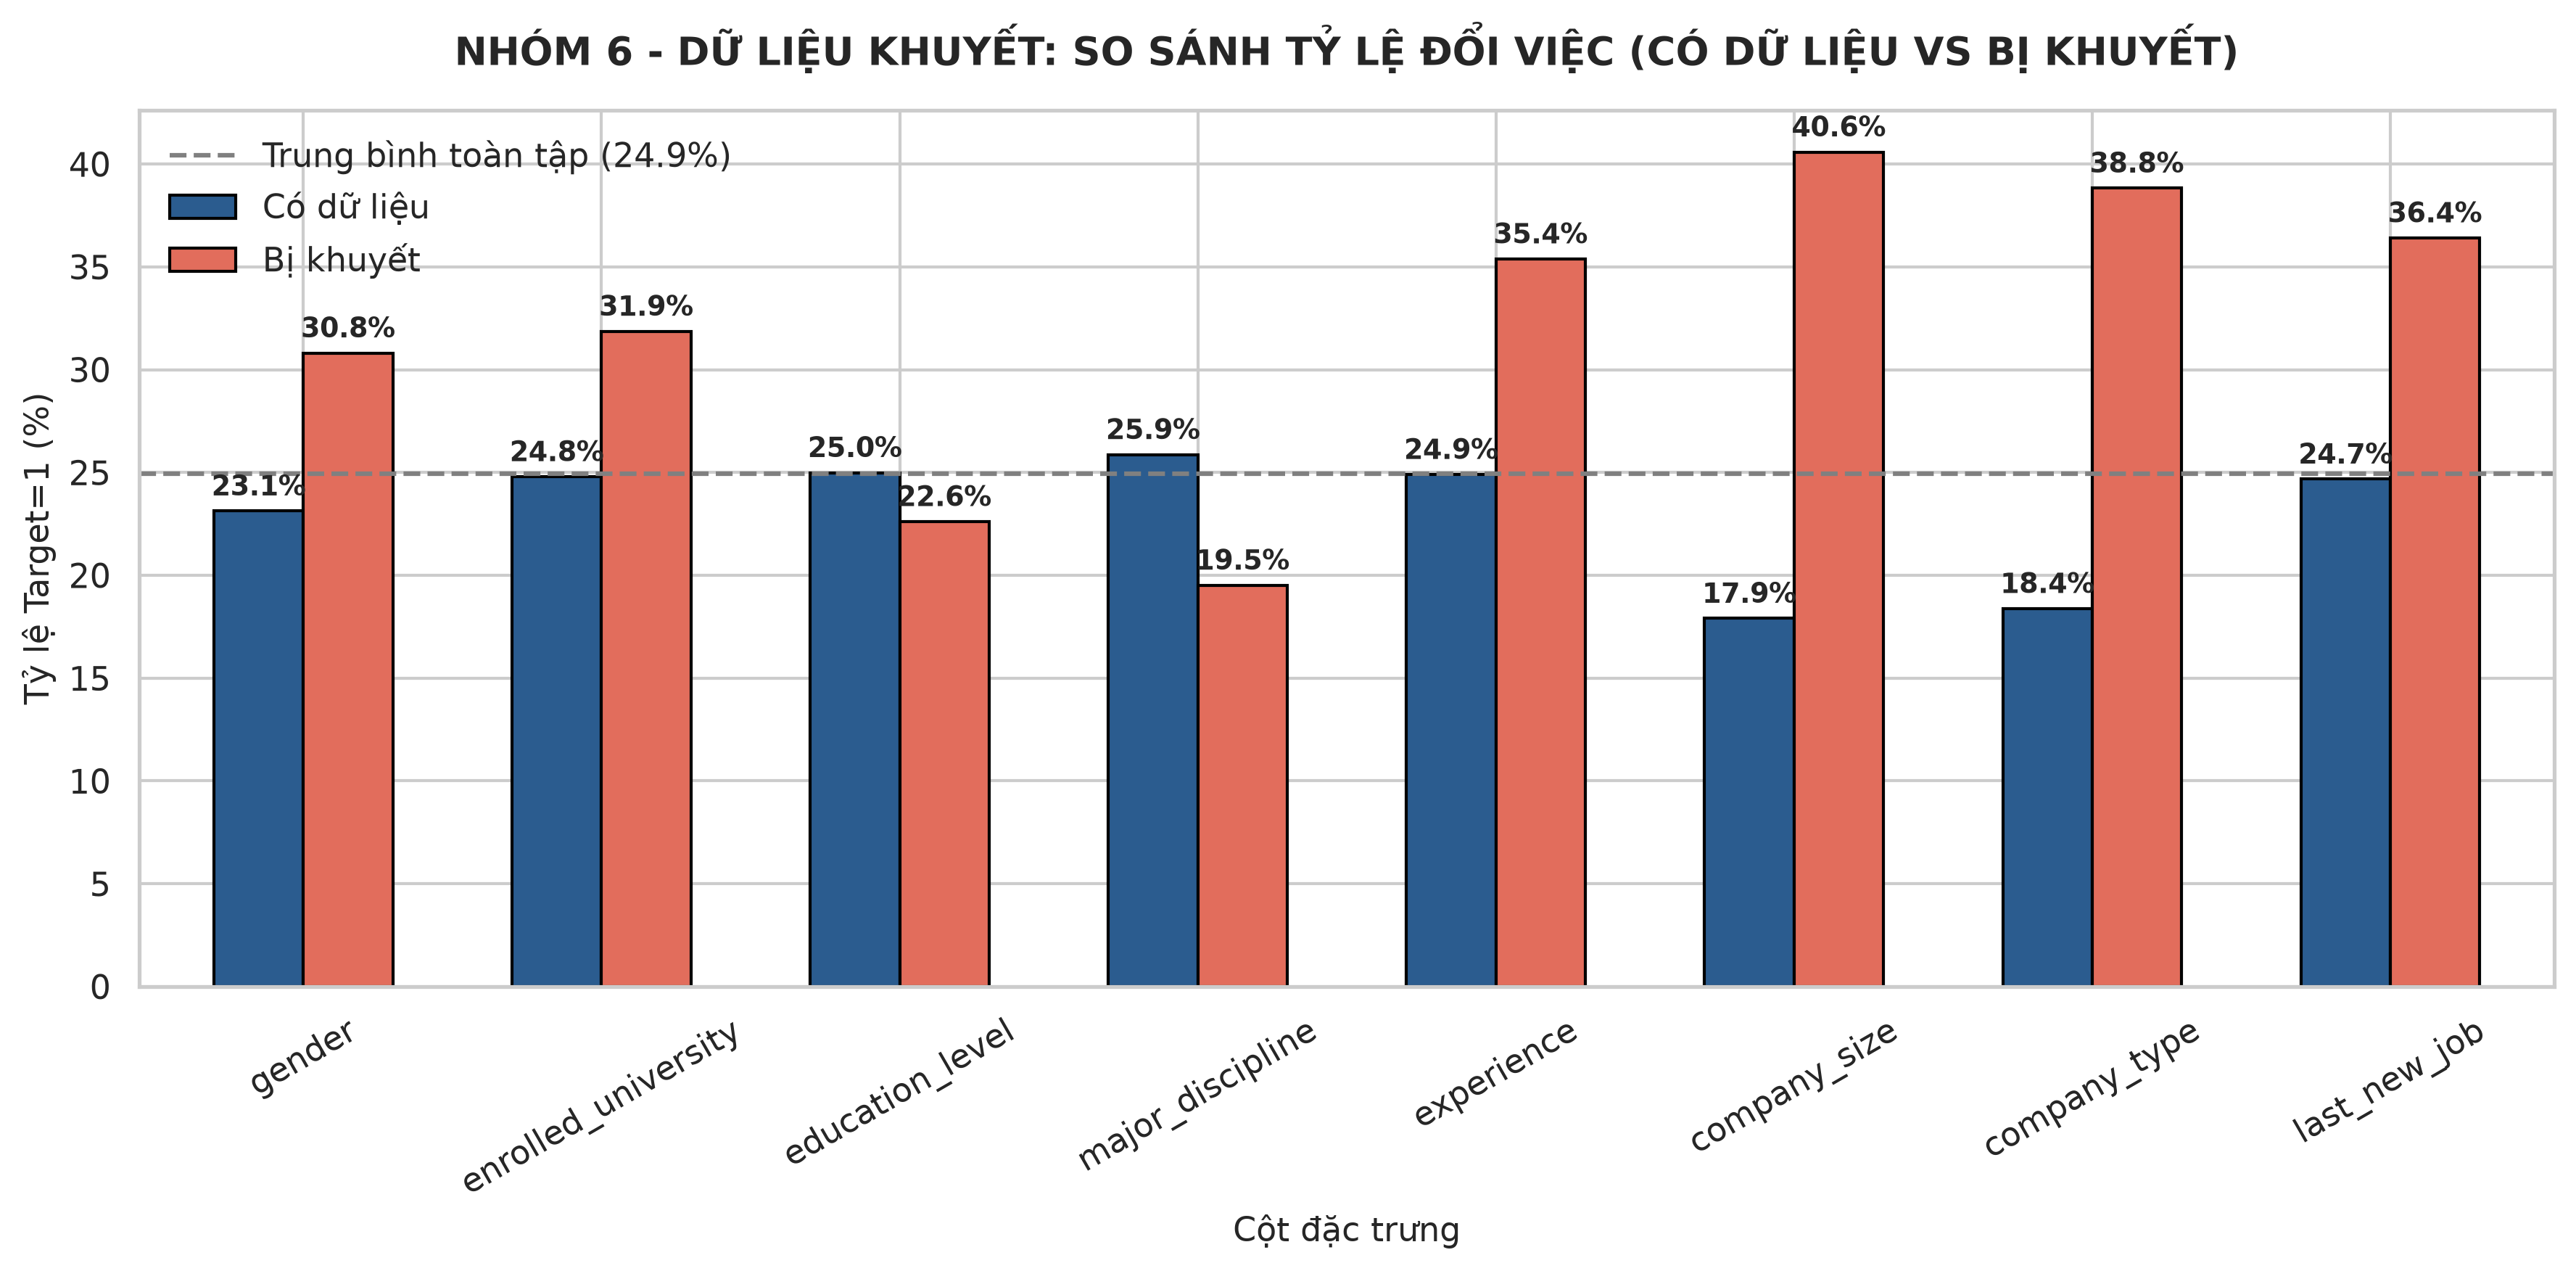

In [9]:
missing_target_rows = []
for col in df_raw.columns[df_raw.isna().any()]:
    grouped = df_raw.groupby(df_raw[col].isna())["target"].agg(["size", "mean"])
    missing_target_rows.append({
        "feature": col,
        "target_rate_observed_pct": grouped.loc[False, "mean"] * 100,
        "target_rate_missing_pct": grouped.loc[True, "mean"] * 100,
        "difference_pp": (grouped.loc[True, "mean"] - grouped.loc[False, "mean"]) * 100,
    })
missingness_target = pd.DataFrame(missing_target_rows).sort_values("difference_pp", ascending=False)
display(missingness_target.round(2))
missingness_target.to_csv(REPORTS_DIR / "missingness_target_rates.csv", index=False)

plot_missingness_vs_target(
    df_raw,
    save_path=str(FIGURES_DIR / "group6_missingness_vs_target.png"),
    show=True,
)

-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group6_correlation_matrix.png


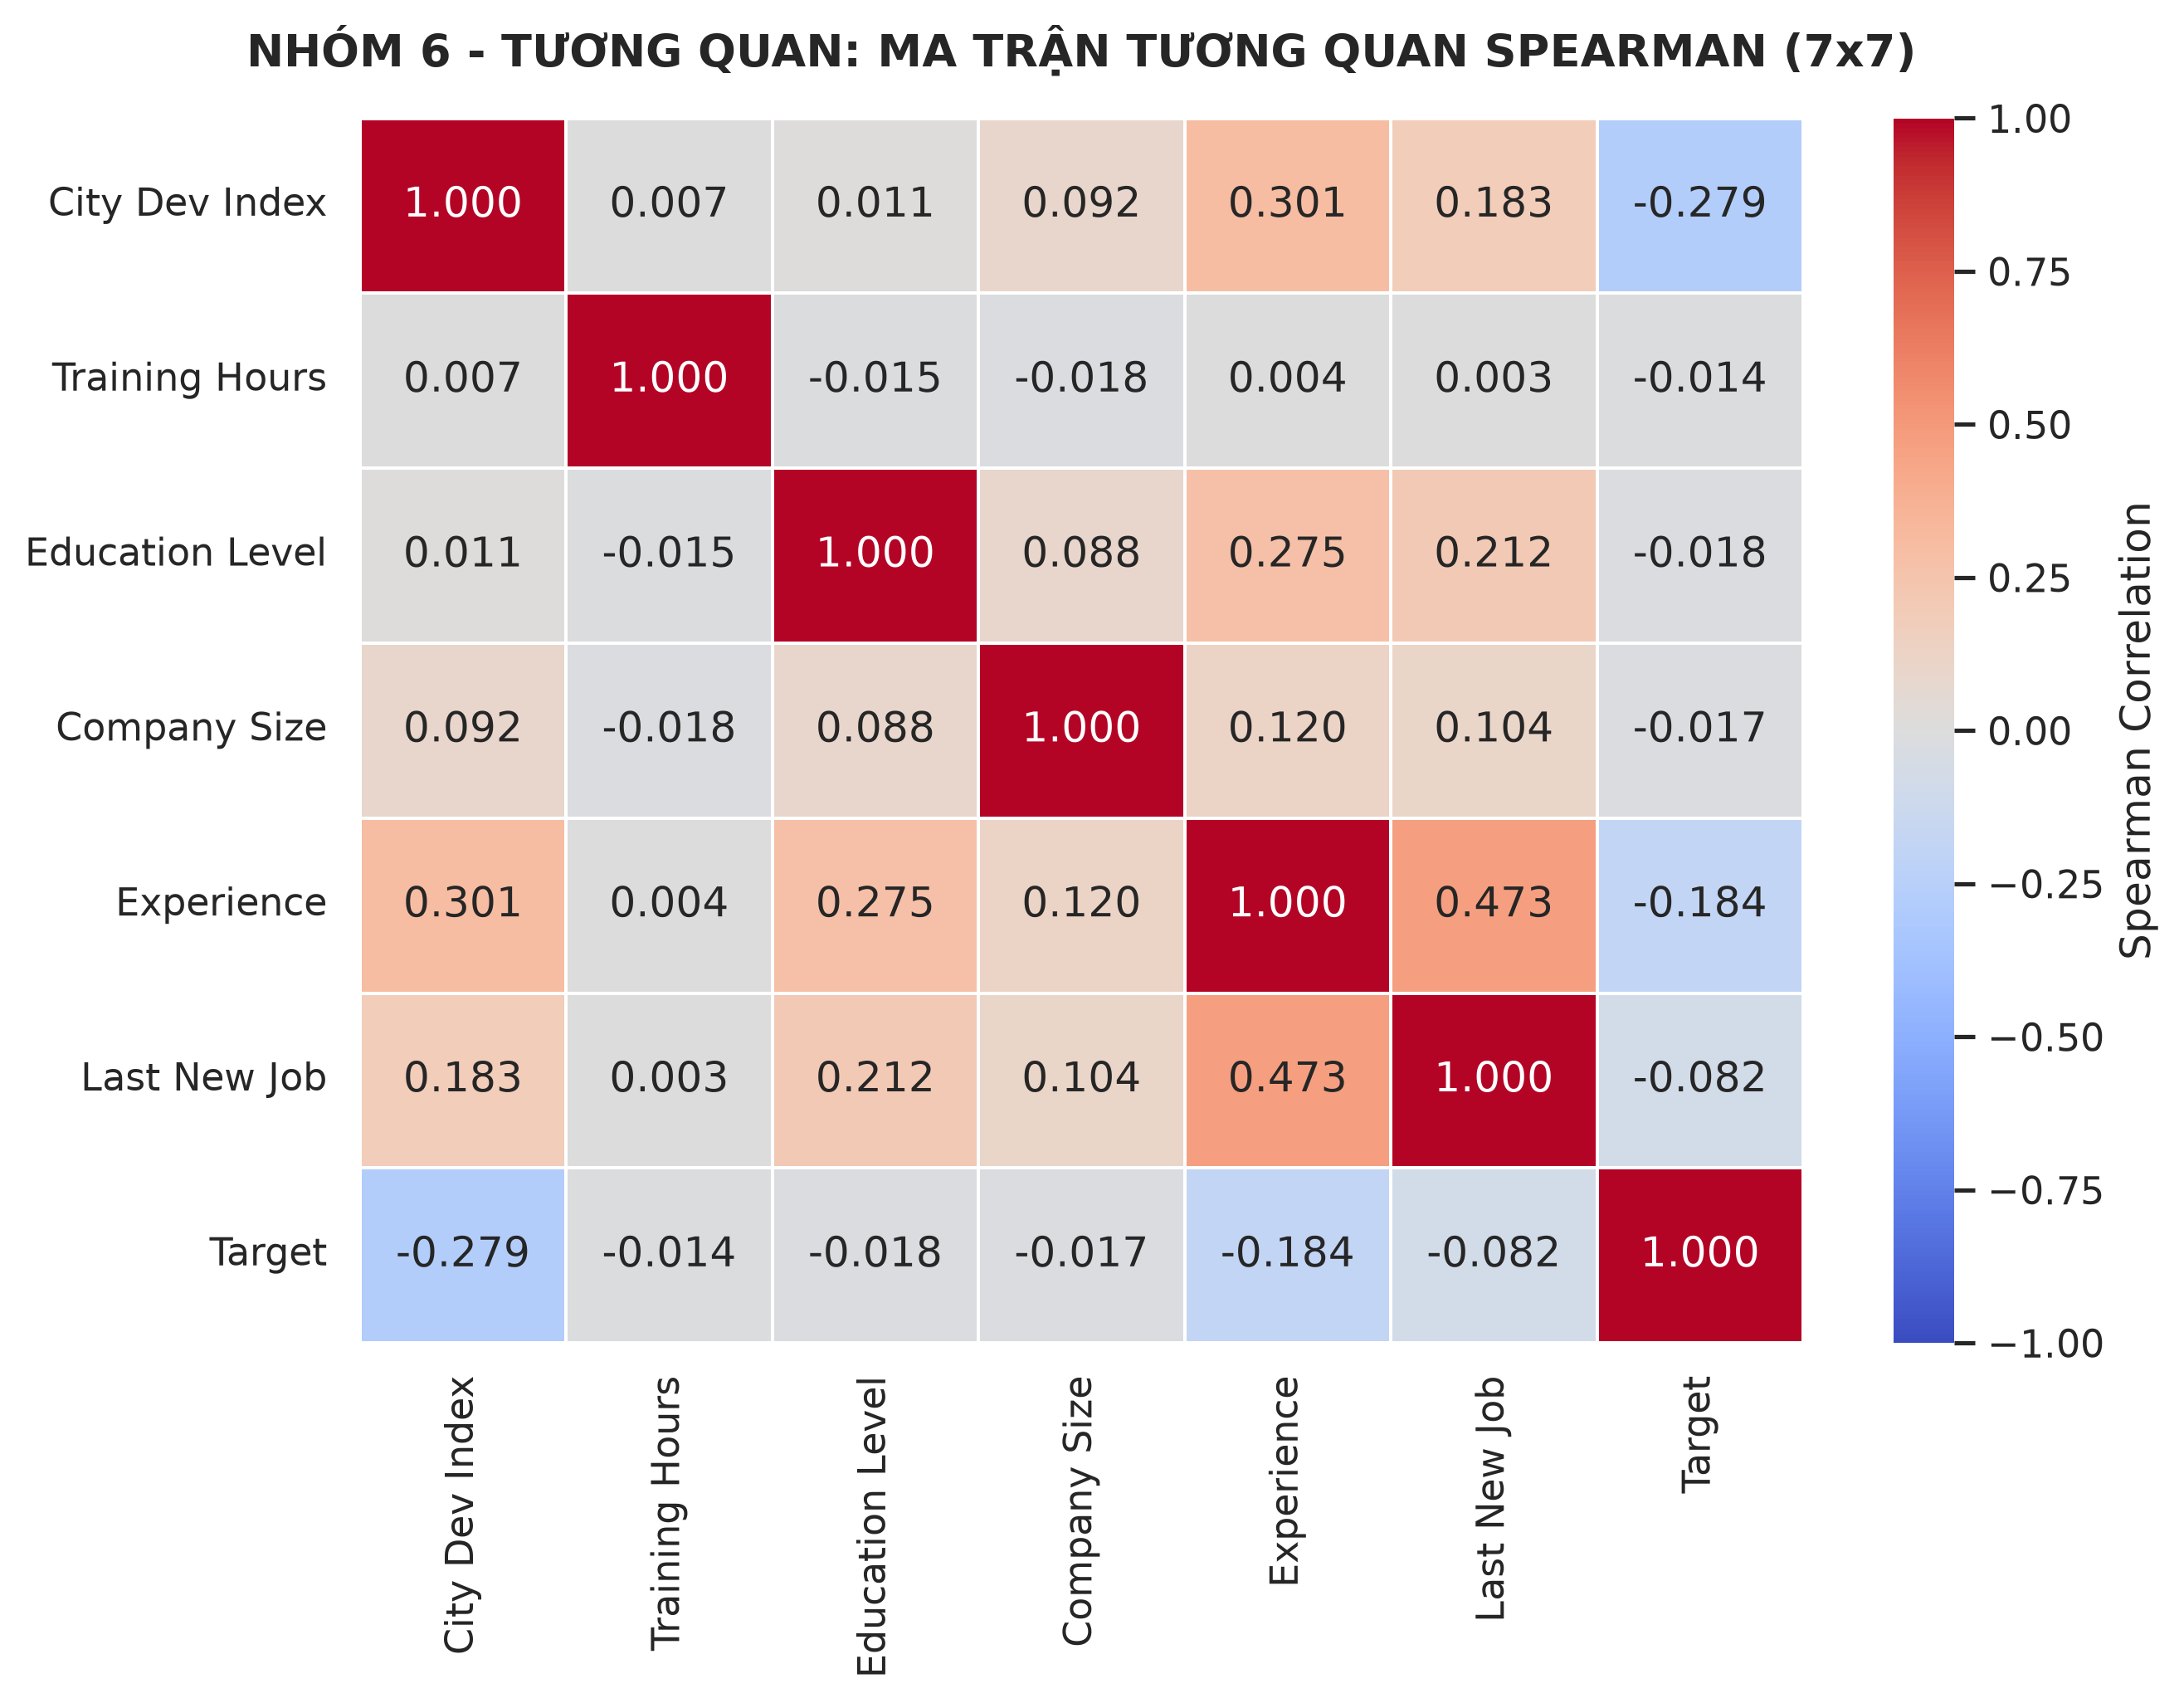

In [10]:
plot_correlation_matrix(
    df_raw,
    save_path=str(FIGURES_DIR / "group6_correlation_matrix.png"),
    show=True,
)

In [11]:
# Tái tạo đầy đủ các biểu đồ chi tiết từ notebook EDA trước đây.
nominal_cols = ["gender", "company_type", "major_discipline", "relevent_experience", "enrolled_university"]
for col in nominal_cols:
    plot_nominal_feature(
        df_raw,
        col,
        save_path=str(FIGURES_DIR / f"group3_nominal_{col}.png"),
        show=False,
    )

for col in ["education_level", "company_size", "experience", "last_new_job"]:
    plot_ordinal_feature(
        df_raw,
        col,
        list(ORDINAL_MAPPINGS[col].keys()),
        save_path=str(FIGURES_DIR / f"group4_ordinal_{col}.png"),
        show=False,
    )
print("Đã tái tạo đầy đủ bộ biểu đồ chi tiết trong reports/figures/.")

-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group3_nominal_gender.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group3_nominal_company_type.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group3_nominal_major_discipline.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group3_nominal_relevent_experience.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group3_nominal_enrolled_university.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group4_ordinal_education_level.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group4_ordinal_company_size.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group4_ordinal_experience.png


-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/reports/figures/group4_ordinal_last_new_job.png
Đã tái tạo đầy đủ bộ biểu đồ chi tiết trong reports/figures/.


### Kết luận EDA và quyết định kỹ thuật

- Target lệch lớp: lớp dương chiếm khoảng 25%; cần ưu tiên ROC-AUC, PR-AUC, F1/Recall thay vì chỉ Accuracy.
- `enrollee_id` chỉ là định danh; `city` dư thừa với `city_development_index`: loại cả hai khỏi mô hình.
- `company_size` và `company_type` có missingness gắn với target: giữ nhóm `Unknown`/giá trị `-1` và tạo cờ missing riêng.
- Các biến có thứ bậc được ánh xạ theo trật tự nghiệp vụ; biến danh nghĩa được one-hot.
- Feature engineering tập trung vào phi tuyến của CDI/training hours, tương tác kinh nghiệm và độ đầy đủ hồ sơ.

## 3. Chia Train / Validation / Test chống rò rỉ dữ liệu

Tỷ lệ **70% / 15% / 15%**, phân tầng theo target. Validation dùng để chọn siêu tham số hoặc early stopping; test không tham gia bất kỳ quyết định mô hình nào.

In [12]:
X_train_raw, X_validation_raw, X_test_raw, y_train, y_validation, y_test = split_train_validation_test(
    df_raw,
    validation_size=0.15,
    test_size=0.15,
    random_state=RANDOM_STATE,
    drop_unnecessary=True,
)

split_summary = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_validation), len(y_test)],
    "positive_count": [int(y_train.sum()), int(y_validation.sum()), int(y_test.sum())],
    "positive_rate_pct": [y_train.mean() * 100, y_validation.mean() * 100, y_test.mean() * 100],
}).set_index("split")
display(split_summary.round(3))

assert set(X_train_raw.index).isdisjoint(X_validation_raw.index)
assert set(X_train_raw.index).isdisjoint(X_test_raw.index)
assert set(X_validation_raw.index).isdisjoint(X_test_raw.index)

,rows,positive_count,positive_rate_pct
split,,,
train,13410,3343,24.929
validation,2874,717,24.948
test,2874,717,24.948


## 4. Tiền xử lý và Feature Engineering

`TabularPreprocessor` thực hiện nhất quán:

- median cho số, mode cho ordinal thông thường;
- `company_size=-1`, `company_type=Unknown` và hai cờ missing để bảo toàn tín hiệu MNAR;
- ordinal mapping và one-hot với `handle_unknown='ignore'`;
- 7 đặc trưng mới không dùng target;
- StandardScaler hoặc MinMaxScaler `[0, 1]`;
- PCA 90%/95% chỉ fit trên train.

In [13]:
engineered_feature_description = pd.DataFrame({
    "feature": ENGINEERED_FEATURES,
    "ý_nghĩa": [
        "log(1 + training_hours), giảm lệch phải",
        "quan hệ phi tuyến của mức phát triển thành phố",
        "tương tác kinh nghiệm × mức phát triển thành phố",
        "cường độ đào tạo trên một đơn vị kinh nghiệm",
        "tần suất chuyển việc tương đối theo kinh nghiệm",
        "tương tác trình độ học vấn × kinh nghiệm",
        "số trường thông tin còn thiếu trong hồ sơ",
    ],
})
display(engineered_feature_description)

,feature,ý_nghĩa
0,training_hours_log1p,"log(1 + training_hours), giảm lệch phải"
1,city_development_index_squared,quan hệ phi tuyến của mức phát triển thành phố
2,experience_x_city_development,tương tác kinh nghiệm × mức phát triển thành phố
3,training_hours_per_experience,cường độ đào tạo trên một đơn vị kinh nghiệm
4,career_mobility_ratio,tần suất chuyển việc tương đối theo kinh nghiệm
5,education_x_experience,tương tác trình độ học vấn × kinh nghiệm
6,profile_missing_count,số trường thông tin còn thiếu trong hồ sơ


In [14]:
configurations = {
    "std": TabularPreprocessor(scaling="standard", add_engineered_features=True, random_state=RANDOM_STATE),
    "minmax": TabularPreprocessor(scaling="minmax", feature_range=(0, 1), add_engineered_features=True, random_state=RANDOM_STATE),
    "pca90": TabularPreprocessor(scaling="standard", pca_variance=0.90, add_engineered_features=True, random_state=RANDOM_STATE),
    "pca95": TabularPreprocessor(scaling="standard", pca_variance=0.95, add_engineered_features=True, random_state=RANDOM_STATE),
}

transformed = {}
for name, preprocessor in configurations.items():
    transformed[f"X_train_{name}"] = preprocessor.fit_transform(X_train_raw).astype(np.float32)
    transformed[f"X_validation_{name}"] = preprocessor.transform(X_validation_raw).astype(np.float32)
    transformed[f"X_test_{name}"] = preprocessor.transform(X_test_raw).astype(np.float32)

feature_names = configurations["std"].get_feature_names_out()
shape_summary = pd.DataFrame([
    {"configuration": name, "train": transformed[f"X_train_{name}"].shape,
     "validation": transformed[f"X_validation_{name}"].shape,
     "test": transformed[f"X_test_{name}"].shape}
    for name in configurations
]).set_index("configuration")
display(shape_summary)
print(f"Tổng số đặc trưng trước PCA: {len(feature_names)}")
display(pd.DataFrame({"feature_name": feature_names}))

,train,validation,test
configuration,,,
std,"(13410, 39)","(2874, 39)","(2874, 39)"
minmax,"(13410, 39)","(2874, 39)","(2874, 39)"
pca90,"(13410, 22)","(2874, 22)","(2874, 22)"
pca95,"(13410, 24)","(2874, 24)","(2874, 24)"


Tổng số đặc trưng trước PCA: 39


,feature_name
0,city_development_index
1,training_hours
2,education_level
3,company_size
4,experience
5,last_new_job
6,company_size_isna
7,company_type_isna
8,gender_Female
9,gender_Male


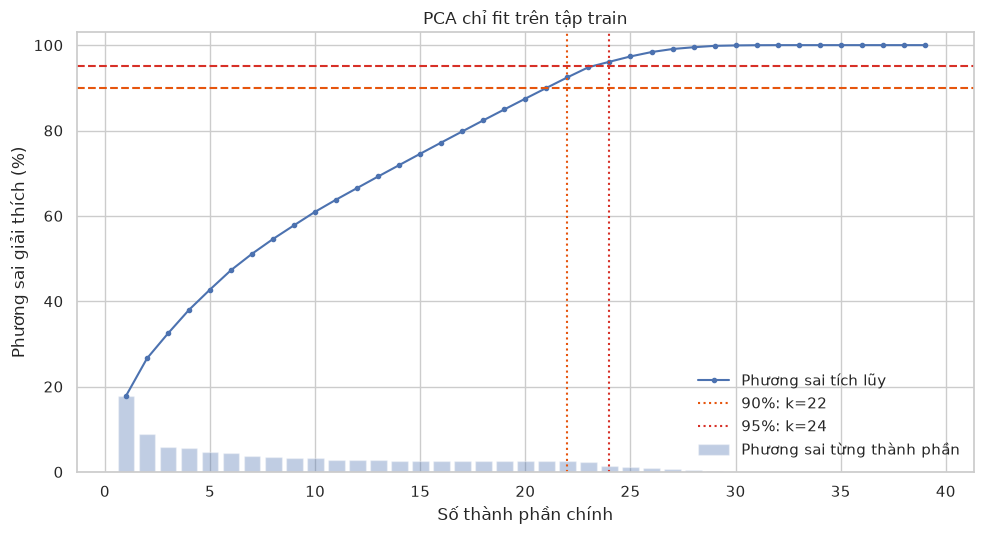

In [15]:
pca_full = PCA(random_state=RANDOM_STATE).fit(transformed["X_train_std"])
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100
k90 = transformed["X_train_pca90"].shape[1]
k95 = transformed["X_train_pca95"].shape[1]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(np.arange(1, len(cumulative_variance) + 1), pca_full.explained_variance_ratio_ * 100,
       alpha=0.35, label="Phương sai từng thành phần")
ax.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance,
        marker="o", markersize=3, label="Phương sai tích lũy")
for threshold, k, color in [(90, k90, "#e6550d"), (95, k95, "#d73027")]:
    ax.axhline(threshold, color=color, linestyle="--")
    ax.axvline(k, color=color, linestyle=":", label=f"{threshold}%: k={k}")
ax.set(xlabel="Số thành phần chính", ylabel="Phương sai giải thích (%)", ylim=(0, 103),
       title="PCA chỉ fit trên tập train")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "group7_pca_scree_plot.png", dpi=300, bbox_inches="tight")
plt.show()

## 5. Xử lý mất cân bằng và gợi ý chọn representation

Notebook không resample trước khi split. Nếu dùng SMOTE/undersampling, thao tác đó phải nằm bên trong từng fold của train. `class_weight` dưới đây là lựa chọn baseline an toàn.

In [16]:
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = {int(c): float(w) for c, w in zip(classes, weights)}
representation_guide = pd.DataFrame({
    "representation": ["std", "minmax", "pca90", "pca95"],
    "khuyến_nghị": [
        "Logistic Regression, SVM, MLP/ReLU",
        "MLP hoặc mô hình cần miền [0, 1]",
        "Mô hình tuyến tính/SVM khi ưu tiên tốc độ",
        "Cấu hình PCA giữ nhiều thông tin hơn",
    ],
})
print("Class weights:", class_weights)
display(representation_guide)

Class weights: {0: 0.6660375484255489, 1: 2.0056835177983845}


,representation,khuyến_nghị
0,std,"Logistic Regression, SVM, MLP/ReLU"
1,minmax,"MLP hoặc mô hình cần miền [0, 1]"
2,pca90,Mô hình tuyến tính/SVM khi ưu tiên tốc độ
3,pca95,Cấu hình PCA giữ nhiều thông tin hơn


## 6. Xuất artefact sẵn sàng huấn luyện

Mảng đặc trưng dùng `float32` để giảm bộ nhớ và tương thích tốt với framework Deep Learning. Preprocessor đã fit được lưu để tái sử dụng đúng cùng phép biến đổi khi suy luận.

In [17]:
feature_names_dict = {
    "full_features": feature_names,
    "engineered_features": ENGINEERED_FEATURES,
    "pca90_features": configurations["pca90"].get_feature_names_out(),
    "pca95_features": configurations["pca95"].get_feature_names_out(),
}
metadata = {
    "dataset": DATA_PATH.name,
    "total_samples": int(len(df_raw)),
    "split": {"train": int(len(y_train)), "validation": int(len(y_validation)), "test": int(len(y_test))},
    "split_ratio": {"train": 0.70, "validation": 0.15, "test": 0.15},
    "positive_rate": {
        "train": float(y_train.mean()),
        "validation": float(y_validation.mean()),
        "test": float(y_test.mean()),
    },
    "random_state": RANDOM_STATE,
    "dropped_columns": ["enrollee_id", "city"],
    "class_weights": class_weights,
    "configurations": {
        "full_features": int(len(feature_names)),
        "pca_90_components": int(k90),
        "pca_95_components": int(k95),
        "dtype": "float32",
    },
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "scikit_learn": sklearn.__version__},
}

save_processed_features(
    output_dir=str(FEATURES_DIR),
    feature_sets=transformed,
    y_train=y_train.to_numpy(dtype=np.int64),
    y_validation=y_validation.to_numpy(dtype=np.int64),
    y_test=y_test.to_numpy(dtype=np.int64),
    feature_names_dict=feature_names_dict,
    metadata=metadata,
)
joblib.dump(configurations, FEATURES_DIR / "preprocessors.joblib")
np.savez_compressed(
    FEATURES_DIR / "split_indices.npz",
    train=X_train_raw.index.to_numpy(),
    validation=X_validation_raw.index.to_numpy(),
    test=X_test_raw.index.to_numpy(),
)
print(f"Đã xuất artefact vào: {FEATURES_DIR}")

-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_train_std.npy [shape: (13410, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_validation_std.npy [shape: (2874, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_test_std.npy [shape: (2874, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_train_minmax.npy [shape: (13410, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_validation_minmax.npy [shape: (2874, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_test_minmax.npy [shape: (2874, 39)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_train_pca90.npy [shape: (13410, 22)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_validation_pca90.npy [shape: (2874, 22)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/features/X_test_pca90.npy [shape: (2874, 22)]
-> Đã lưu: /home/puffy/ML/HCMUT/BTL/261-ML-Assignmen

In [18]:
loaded = load_processed_features(str(FEATURES_DIR))
checks = []
expected_rows = {"train": len(y_train), "validation": len(y_validation), "test": len(y_test)}
for name, arr in sorted(loaded.items()):
    split = next((s for s in expected_rows if f"_{s}_" in f"_{name}_"), None)
    row_ok = split is None or arr.shape[0] == expected_rows[split]
    checks.append({
        "name": name,
        "shape": str(arr.shape),
        "dtype": str(arr.dtype),
        "finite": bool(np.isfinite(arr).all()),
        "row_count_ok": bool(row_ok),
    })
integrity = pd.DataFrame(checks)
display(integrity)
assert integrity["finite"].all() and integrity["row_count_ok"].all()
assert len(configurations["std"].get_feature_names_out()) == loaded["X_train_std"].shape[1]
print("KIỂM ĐỊNH THÀNH CÔNG: không NaN/Inf, số dòng và số đặc trưng nhất quán.")

,name,shape,dtype,finite,row_count_ok
0,X_test_minmax,"(2874, 39)",float32,True,True
1,X_test_pca90,"(2874, 22)",float32,True,True
2,X_test_pca95,"(2874, 24)",float32,True,True
3,X_test_std,"(2874, 39)",float32,True,True
4,X_train_minmax,"(13410, 39)",float32,True,True
5,X_train_pca90,"(13410, 22)",float32,True,True
6,X_train_pca95,"(13410, 24)",float32,True,True
7,X_train_std,"(13410, 39)",float32,True,True
8,X_validation_minmax,"(2874, 39)",float32,True,True
9,X_validation_pca90,"(2874, 22)",float32,True,True


KIỂM ĐỊNH THÀNH CÔNG: không NaN/Inf, số dòng và số đặc trưng nhất quán.


## 7. Huấn luyện và chọn cấu hình trên validation

Hai mô hình truyền thống được lựa chọn vì bổ trợ nhau:

- **Logistic Regression**: baseline tuyến tính có regularization, nhanh và dễ diễn giải.
- **Random Forest**: mô hình cây phi tuyến, học được tương tác và ít nhạy với phân phối đặc trưng.

Các tổ hợp representation/siêu tham số nằm trong `configs/model_experiments.json`. Mọi ứng viên chỉ được đánh giá trên validation; **PR-AUC** là tiêu chí chọn chính vì lớp dương chỉ chiếm khoảng 25%. Ngưỡng phân loại tối ưu F1 cũng chỉ được học từ validation.

In [19]:
experiment_config = load_experiment_config(MODEL_CONFIG_PATH)
validation_results, fitted_candidates = run_validation_experiments(
    transformed, y_train, y_validation, experiment_config
)
validation_results.to_csv(REPORTS_DIR / "model_validation_results.csv", index=False)
display(validation_results.round(4))

best_candidates = select_best_candidates(
    validation_results, primary_metric=experiment_config["selection_metric"]
)
print("Cấu hình được khóa cho từng thuật toán:")
display(best_candidates.round(4))

,candidate_id,model,representation,parameters,fit_seconds,validation_threshold,validation_roc_auc,validation_pr_auc,validation_accuracy_at_0_5,validation_f1_at_0_5,validation_precision,validation_recall,validation_f1,validation_balanced_accuracy
0,logistic_regression__06,logistic_regression,std,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.1113,0.5182,0.7830,0.5262,0.7397,0.5877,0.4953,0.7350,0.5918,0.7430
1,logistic_regression__05,logistic_regression,std,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.1068,0.5245,0.7816,0.5254,0.7349,0.5822,0.4939,0.7322,0.5899,0.7414
2,logistic_regression__03,logistic_regression,std,"{""C"": 10.0, ""class_weight"": null}",0.1041,0.2831,0.7806,0.5249,0.7683,0.3571,0.5030,0.7071,0.5878,0.7374
3,logistic_regression__02,logistic_regression,std,"{""C"": 1.0, ""class_weight"": null}",0.0944,0.2834,0.7792,0.5245,0.7676,0.3589,0.4985,0.7057,0.5843,0.7349
4,logistic_regression__04,logistic_regression,std,"{""C"": 0.1, ""class_weight"": ""balanced""}",0.0525,0.5085,0.7763,0.5214,0.7209,0.5684,0.4671,0.7336,0.5708,0.7277
5,logistic_regression__01,logistic_regression,std,"{""C"": 0.1, ""class_weight"": null}",0.0729,0.2429,0.7746,0.5205,0.7669,0.3558,0.4594,0.7503,0.5699,0.7284
6,logistic_regression__13,logistic_regression,pca95,"{""C"": 0.1, ""class_weight"": null}",0.0153,0.3105,0.7615,0.5102,0.7704,0.3666,0.4769,0.6346,0.5446,0.7016
7,logistic_regression__15,logistic_regression,pca95,"{""C"": 10.0, ""class_weight"": null}",0.0149,0.3094,0.7615,0.5102,0.7697,0.3635,0.4764,0.6346,0.5443,0.7014
8,logistic_regression__14,logistic_regression,pca95,"{""C"": 1.0, ""class_weight"": null}",0.0153,0.3095,0.7615,0.5102,0.7697,0.3635,0.4769,0.6346,0.5446,0.7016
9,logistic_regression__17,logistic_regression,pca95,"{""C"": 1.0, ""class_weight"": ""balanced""}",0.0174,0.5582,0.7621,0.5090,0.7008,0.5416,0.4662,0.6541,0.5444,0.7026


Cấu hình được khóa cho từng thuật toán:


,candidate_id,model,representation,parameters,fit_seconds,validation_threshold,validation_roc_auc,validation_pr_auc,validation_accuracy_at_0_5,validation_f1_at_0_5,validation_precision,validation_recall,validation_f1,validation_balanced_accuracy
0,random_forest__01,random_forest,std,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.3859,0.6148,0.7925,0.5372,0.7641,0.6099,0.5624,0.6918,0.6204,0.7564
1,logistic_regression__06,logistic_regression,std,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.1113,0.5182,0.7830,0.5262,0.7397,0.5877,0.4953,0.7350,0.5918,0.7430


## 8. Đánh giá cuối trên test và phân tích mô hình

Sau khi khóa representation, siêu tham số và ngưỡng bằng validation, mỗi mô hình được fit lại trên train + validation. Test chỉ được mở đúng một lần tại đây. Báo cáo đồng thời Accuracy, Precision, Recall, Specificity, F1, Balanced Accuracy, ROC-AUC và PR-AUC; confusion matrix cho thấy trực tiếp từng loại lỗi.

In [20]:
test_results, final_models = refit_and_evaluate_on_test(
    best_candidates, fitted_candidates, transformed,
    y_train, y_validation, y_test,
)
test_results.to_csv(REPORTS_DIR / "model_test_results.csv", index=False)
display(test_results.round(4))

feature_names_by_representation = {
    name: preprocessor.get_feature_names_out()
    for name, preprocessor in configurations.items()
}
importance_results = feature_importance_table(
    final_models, feature_names_by_representation
)
importance_results.to_csv(REPORTS_DIR / "model_feature_importance.csv", index=False)
print("Top 10 đặc trưng/thành phần của mỗi mô hình:")
display(importance_results.groupby("model", group_keys=False).head(10).round(4))

plot_model_comparison(final_models, y_test, FIGURES_DIR)
artifact_paths = save_model_artifacts(
    MODELS_DIR, final_models, configurations, test_results
)
print("Đã lưu mô hình và biểu đồ:", artifact_paths)

,model,candidate_id,representation,parameters,test_threshold,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_specificity,test_f1,test_roc_auc,test_pr_auc,test_tn,test_fp,test_fn,test_tp
0,logistic_regression,logistic_regression__06,std,"{""C"": 10.0, ""class_weight"": ""balanced""}",0.5182,0.7610,0.7644,0.5139,0.7713,0.7575,0.6168,0.7963,0.5288,1634,523,164,553
1,random_forest,random_forest__01,std,"{""class_weight"": ""balanced"", ""max_depth"": 8, ""...",0.6148,0.7947,0.7725,0.5692,0.7280,0.8169,0.6389,0.8120,0.5414,1762,395,195,522


Top 10 đặc trưng/thành phần của mỗi mô hình:


,model,representation,feature,signed_effect,importance,rank
0,random_forest,std,city_development_index,0.2103,0.2103,1
1,random_forest,std,city_development_index_squared,0.2019,0.2019,2
2,random_forest,std,experience_x_city_development,0.0676,0.0676,3
3,random_forest,std,company_size_isna,0.0659,0.0659,4
4,random_forest,std,company_size,0.0642,0.0642,5
5,random_forest,std,profile_missing_count,0.0515,0.0515,6
6,random_forest,std,company_type_isna,0.0358,0.0358,7
7,random_forest,std,company_type_Unknown,0.0336,0.0336,8
8,random_forest,std,experience,0.0282,0.0282,9
9,random_forest,std,education_x_experience,0.0275,0.0275,10


Đã lưu mô hình và biểu đồ: {'random_forest': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/random_forest.joblib', 'logistic_regression': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/logistic_regression.joblib', 'manifest': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/model_manifest.json'}


## 9. Phân tích kết quả và hạn chế

- Random Forest có kết quả tổng thể tốt hơn (test ROC-AUC 0,8120; PR-AUC 0,5414; F1 0,6389), cho thấy quan hệ phi tuyến/tương tác có ích.
- Logistic Regression có recall cao hơn (0,7713 so với 0,7280), phù hợp hơn nếu chi phí bỏ sót ứng viên có nhu cầu chuyển việc cao; đổi lại precision thấp hơn.
- `city_development_index`, bình phương của nó, tương tác với kinh nghiệm và các tín hiệu missing của công ty nằm trong nhóm quan trọng nhất. Điều này củng cố các quyết định EDA/feature engineering, nhưng importance và coefficient chỉ là liên hệ dự báo, không phải quan hệ nhân quả.
- Kết quả dựa trên một holdout split và một dataset tự khai báo; cần cross-validation lồng hoặc kiểm định ngoài mẫu trước khi dùng cho quyết định nhân sự thực tế. Các thuộc tính nhân khẩu học cũng cần được audit fairness.

## 10. Kiểm tra artefact suy luận từ dữ liệu thô

Mỗi file `.joblib` chứa cả preprocessor đã fit, mô hình, representation và ngưỡng đã khóa. Vì vậy suy luận nhận trực tiếp các cột dữ liệu thô và áp dụng đúng biến đổi lúc train.

In [21]:
champion_name = best_candidates.sort_values(
    experiment_config["selection_metric"], ascending=False
).iloc[0]["model"]
champion_artifact = joblib.load(MODELS_DIR / f"{champion_name}.joblib")
inference_example = predict_from_raw_dataframe(
    champion_artifact, df_raw.drop(columns="target").head(5)
)
display(inference_example)
assert len(inference_example) == 5
assert inference_example["probability_target_1"].between(0, 1).all()
print(f"Kiểm tra suy luận thành công với {champion_name}.")

,probability_target_1,prediction
0,0.755598,1
1,0.306641,0
2,0.840373,1
3,0.643941,1
4,0.209397,0


Kiểm tra suy luận thành công với random_forest.


## 11. Deep Learning: ResNet baseline và TabM

Cả hai mô hình dùng embedding cho 10 trường categorical (bao gồm `city`) và 13 numerical/engineered features đã chuẩn hóa. **ResNet** là residual-MLP baseline mạnh cho dữ liệu bảng. **TabM** dùng các lớp BatchEnsemble rank-one để huấn luyện nhiều MLP member song song trong một mạng chia sẻ trọng số; xác suất các member được trung bình khi suy luận.

Quy trình chống leakage giống pipeline truyền thống: vocabulary, median, mean và standard deviation chỉ fit trên train; cấu hình, checkpoint early stopping và threshold chỉ chọn bằng validation; test chỉ dùng sau khi khóa độc lập một cấu hình cho mỗi thuật toán.

In [22]:
with DEEP_CONFIG_PATH.open(encoding="utf-8") as handle:
    deep_config = json.load(handle)

# Split lại cùng seed nhưng giữ city cho categorical embedding.
deep_X_train_raw, deep_X_validation_raw, deep_X_test_raw, deep_y_train, deep_y_validation, deep_y_test = split_train_validation_test(
    df_raw, validation_size=0.15, test_size=0.15,
    random_state=RANDOM_STATE, drop_unnecessary=False,
)
assert deep_X_train_raw.index.equals(X_train_raw.index)
assert deep_X_validation_raw.index.equals(X_validation_raw.index)
assert deep_X_test_raw.index.equals(X_test_raw.index)

deep_preprocessor = DeepTabularPreprocessor()
deep_train = deep_preprocessor.fit_transform(deep_X_train_raw)
deep_validation = deep_preprocessor.transform(deep_X_validation_raw)
deep_test = deep_preprocessor.transform(deep_X_test_raw)
DEEP_DEVICE = torch.device("cpu")  # CPU cho kết quả Run All tái lập giữa Local/Colab
torch.set_num_threads(min(8, os.cpu_count() or 1))
print({
    "algorithms": list(deep_config["models"]),
    "device": str(DEEP_DEVICE),
    "categorical_shape": deep_train[0].shape,
    "numerical_shape": deep_train[1].shape,
    "cardinalities": deep_preprocessor.cardinalities_,
})

{'algorithms': ['resnet', 'tabm'], 'device': 'cpu', 'categorical_shape': (13410, 10), 'numerical_shape': (13410, 13), 'cardinalities': [124, 5, 4, 5, 7, 8, 24, 10, 8, 8]}


## 12. Tuning ResNet và TabM chỉ trên validation

Early stopping và chọn candidate đều dùng PR-AUC validation, với ROC-AUC/F1 làm tie-breaker. ResNet và TabM được chọn độc lập; `member_count` của TabM là một phần siêu tham số và không sử dụng test để quyết định. Trên CPU, cell này có thể cần vài phút.

In [23]:
deep_validation_results, deep_fitted_candidates = run_deep_validation_experiments(
    deep_train, deep_y_train, deep_validation, deep_y_validation,
    deep_preprocessor.cardinalities_,
    {name: spec["candidates"] for name, spec in deep_config["models"].items()},
    device=DEEP_DEVICE, verbose=True,
)
deep_validation_results.to_csv(REPORTS_DIR / "deep_validation_results.csv", index=False)
display(deep_validation_results.round(4))

best_deep_candidates = select_best_deep_candidates(deep_validation_results)
display(best_deep_candidates.round(4))
selected_histories = pd.concat(
    [deep_fitted_candidates[row.candidate_id]["history"].assign(
        candidate_id=row.candidate_id, algorithm=row.algorithm
     ) for row in best_deep_candidates.itertuples()],
    ignore_index=True,
)
selected_histories.to_csv(REPORTS_DIR / "deep_training_history.csv", index=False)
print("Validation-selected candidates:", best_deep_candidates["candidate_id"].tolist())

[1/6] Training resnet__01 (ResNet) ...


  best_epoch=12 | PR-AUC=0.5543 | ROC-AUC=0.7981 | F1=0.6178
[2/6] Training resnet__02 (ResNet) ...


  best_epoch=5 | PR-AUC=0.5505 | ROC-AUC=0.7977 | F1=0.6113
[3/6] Training resnet__03 (ResNet) ...


  best_epoch=7 | PR-AUC=0.5583 | ROC-AUC=0.7985 | F1=0.6193
[4/6] Training tabm__01 (TabM) ...


  best_epoch=6 | PR-AUC=0.5547 | ROC-AUC=0.8003 | F1=0.6212
[5/6] Training tabm__02 (TabM) ...


  best_epoch=7 | PR-AUC=0.5553 | ROC-AUC=0.8012 | F1=0.6196
[6/6] Training tabm__03 (TabM) ...


  best_epoch=7 | PR-AUC=0.5561 | ROC-AUC=0.7982 | F1=0.6213


,candidate_id,algorithm,algorithm_key,parameters,parameter_count,best_epoch,fit_seconds,validation_threshold,validation_accuracy,validation_balanced_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc
0,resnet__03,ResNet,resnet,"{""batch_size"": 512, ""d_block"": 256, ""d_hidden_...",838833,7,15.0124,0.3254,0.7857,0.7567,0.5560,0.6987,0.6193,0.7985,0.5583
1,resnet__01,ResNet,resnet,"{""batch_size"": 512, ""d_block"": 128, ""d_hidden_...",146393,12,6.7480,0.4884,0.7933,0.7520,0.5735,0.6695,0.6178,0.7981,0.5543
2,resnet__02,ResNet,resnet,"{""batch_size"": 512, ""d_block"": 192, ""d_hidden_...",473989,5,10.1401,0.2525,0.7752,0.7530,0.5376,0.7085,0.6113,0.7977,0.5505
3,tabm__03,TabM,tabm,"{""batch_size"": 512, ""d_block"": 192, ""d_hidden_...",521149,7,68.1402,0.4168,0.7888,0.7573,0.5621,0.6946,0.6213,0.7982,0.5561
4,tabm__02,TabM,tabm,"{""batch_size"": 512, ""d_block"": 128, ""d_hidden_...",197493,7,54.2773,0.3014,0.7808,0.7590,0.5463,0.7155,0.6196,0.8012,0.5553
5,tabm__01,TabM,tabm,"{""batch_size"": 512, ""d_block"": 128, ""d_hidden_...",168657,6,24.0832,0.3485,0.7815,0.7604,0.5473,0.7183,0.6212,0.8003,0.5547


,candidate_id,algorithm,algorithm_key,parameters,parameter_count,best_epoch,fit_seconds,validation_threshold,validation_accuracy,validation_balanced_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_pr_auc
0,resnet__03,ResNet,resnet,"{""batch_size"": 512, ""d_block"": 256, ""d_hidden_...",838833,7,15.0124,0.3254,0.7857,0.7567,0.5560,0.6987,0.6193,0.7985,0.5583
1,tabm__03,TabM,tabm,"{""batch_size"": 512, ""d_block"": 192, ""d_hidden_...",521149,7,68.1402,0.4168,0.7888,0.7573,0.5621,0.6946,0.6213,0.7982,0.5561


Validation-selected candidates: ['resnet__03', 'tabm__03']


## 13. Đánh giá deep model trên test khóa kín

Chỉ hai candidate và threshold đã khóa ở trên được đánh giá. Bảng so sánh dùng đúng test split của hai mô hình truyền thống. PR-AUC là metric chính; F1 kiểm tra chất lượng quyết định tại threshold validation.

,algorithm,test_accuracy,test_balanced_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
0,logistic_regression,0.7610,0.7644,0.5139,0.7713,0.6168,0.7963,0.5288
1,random_forest,0.7947,0.7725,0.5692,0.7280,0.6389,0.8120,0.5414
2,ResNet,0.7944,0.7778,0.5669,0.7448,0.6438,0.8087,0.5657
3,TabM,0.7958,0.7759,0.5702,0.7364,0.6427,0.8093,0.5576


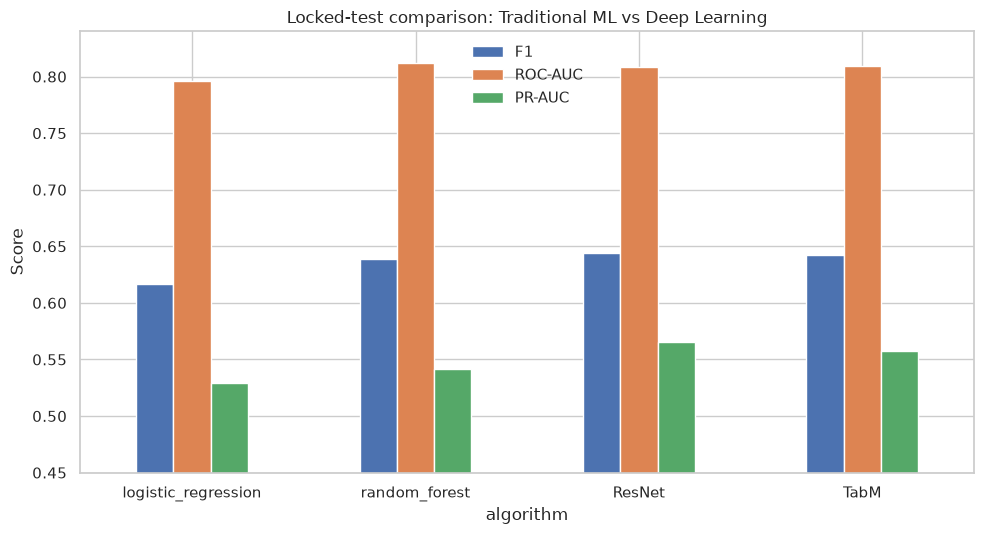

So sánh test đã hoàn tất; không dùng test để chọn cấu hình.
Đã lưu: {'preprocessor': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/deep_tabular_preprocessor.joblib', 'resnet': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/resnet.pt', 'tabm': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/tabm.pt', 'manifest': '/home/puffy/ML/HCMUT/BTL/261-ML-Assignment-G3/models/deep_models_manifest.json'}


In [24]:
deep_test_results, final_deep_models = evaluate_deep_models_on_test(
    best_deep_candidates, deep_fitted_candidates, deep_test, deep_y_test,
    device=DEEP_DEVICE,
)
deep_test_results.to_csv(REPORTS_DIR / "deep_test_results.csv", index=False)
plot_deep_model_results(final_deep_models, deep_y_test, FIGURES_DIR)
deep_artifact_paths = save_deep_model_artifacts(
    MODELS_DIR, deep_preprocessor, final_deep_models
)

comparison_rows = test_results[["model", "test_accuracy", "test_balanced_accuracy",
                                "test_precision", "test_recall", "test_f1",
                                "test_roc_auc", "test_pr_auc"]].rename(columns={"model": "algorithm"})
comparison_rows = pd.concat([comparison_rows, deep_test_results[[
    "algorithm", "test_accuracy", "test_balanced_accuracy", "test_precision",
    "test_recall", "test_f1", "test_roc_auc", "test_pr_auc",
]]], ignore_index=True)
comparison_rows.to_csv(REPORTS_DIR / "all_models_test_comparison.csv", index=False)
display(comparison_rows.round(4))
metric_columns = ["test_f1", "test_roc_auc", "test_pr_auc"]
comparison_axis = comparison_rows.set_index("algorithm")[metric_columns].plot(
    kind="bar", figsize=(10, 5.5), ylim=(0.45, 0.84), rot=0,
    title="Locked-test comparison: Traditional ML vs Deep Learning",
)
comparison_axis.set_ylabel("Score")
comparison_axis.legend(["F1", "ROC-AUC", "PR-AUC"])
comparison_axis.figure.tight_layout()
comparison_axis.figure.savefig(
    FIGURES_DIR / "all_models_metric_comparison.png", dpi=300, bbox_inches="tight"
)
plt.show()

assert set(deep_test_results["algorithm_key"]) == {"resnet", "tabm"}
print("So sánh test đã hoàn tất; không dùng test để chọn cấu hình.")
print("Đã lưu:", deep_artifact_paths)

## 14. Nạp checkpoint deep learning và suy luận dữ liệu thô

Mỗi checkpoint dùng `state_dict` thay vì pickle toàn bộ model; hai mô hình chia sẻ preprocessor train-only. Với TabM, hàm suy luận trung bình xác suất các member nội bộ rồi áp dụng threshold validation đã khóa.

In [25]:
deep_inference_examples = {}
for algorithm in ("resnet", "tabm"):
    loaded_model, loaded_deep_preprocessor, loaded_checkpoint = load_deep_model_artifact(
        MODELS_DIR / f"{algorithm}.pt",
        MODELS_DIR / "deep_tabular_preprocessor.joblib",
        device=DEEP_DEVICE,
    )
    predictions = predict_deep_from_raw_dataframe(
        loaded_model, loaded_deep_preprocessor, loaded_checkpoint,
        df_raw.drop(columns="target").head(5), device=DEEP_DEVICE,
    )
    assert predictions["probability_target_1"].between(0, 1).all()
    deep_inference_examples[algorithm] = predictions
    print(algorithm)
    display(predictions)

resnet


,probability_target_1,prediction
0,0.610733,1
1,0.091032,0
2,0.633099,1
3,0.619296,1
4,0.078079,0


tabm


,probability_target_1,prediction
0,0.629954,1
1,0.090575,0
2,0.634605,1
3,0.650931,1
4,0.074948,0


## 15. Kết quả bàn giao

- EDA, preprocessing, feature engineering và bốn representation truyền thống chống leakage.
- Tuning Logistic Regression và Random Forest; test report, feature importance và inference bundle.
- ResNet residual-MLP làm deep-learning baseline và TabM parameter-efficient ensemble làm mô hình chính.
- Mỗi thuật toán được tuning và khóa checkpoint/threshold độc lập bằng validation PR-AUC trước khi đánh giá test.
- Bảng test cuối báo cáo đầy đủ Accuracy, Balanced Accuracy, Precision, Recall, F1, ROC-AUC và PR-AUC; không giả định deep learning thắng trên mọi metric.
- Toàn bộ feature, model, preprocessor, checkpoint, history, bảng metric và biểu đồ được lưu để tái lập và suy luận dữ liệu thô.

## 16. Audit độ tin cậy, calibration, fairness và độ ổn định

Các phân tích sau được tạo tự động từ các cấu hình đã khóa:

- repeated 5-fold cross-validation (3 lần lặp) chỉ trên train+validation cho hai mô hình truyền thống;
- ablation trên validation cho engineered features và missing indicators;
- bootstrap 95% CI, calibration và audit theo nhóm giới tính trên dự đoán test đã khóa;
- permutation importance trên validation và checksum phục vụ kiểm toán.

Các kết quả test bổ sung chỉ mô tả độ bất định/rủi ro; **không dùng để chọn lại mô hình hay threshold**.


In [26]:
from scripts.generate_audits import main as generate_audits

generate_audits()
display(pd.read_csv(REPORTS_DIR / "repeated_cv_summary.csv").round(4))
display(pd.read_csv(REPORTS_DIR / "feature_ablation_results.csv").round(4))
display(pd.read_csv(REPORTS_DIR / "model_calibration_metrics.csv").round(4))
display(pd.read_csv(REPORTS_DIR / "model_paired_differences.csv").round(4))
display(pd.read_csv(REPORTS_DIR / "gender_subgroup_audit.csv").round(4))
print("Audit artifacts and provenance generated successfully.")

Generated calibration, uncertainty, subgroup, ablation, CV, and provenance audits.


,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,f1_at_0_5_mean,f1_at_0_5_std
0,logistic_regression,0.5245,0.0115,0.7866,0.0065,0.5983,0.0087
1,random_forest,0.5457,0.0148,0.8012,0.0078,0.6213,0.0094


,variant,feature_count,validation_threshold,validation_f1,validation_pr_auc,validation_roc_auc
0,full,39,0.6148,0.6204,0.5372,0.7925
1,without_engineered_features,32,0.6503,0.6101,0.5370,0.7909
2,without_missing_indicators,37,0.5676,0.6199,0.5295,0.7924
3,without_engineered_or_missing,30,0.6302,0.6133,0.5409,0.7928


,model,brier_score,ece_10_bin
0,logistic_regression,0.1839,0.1960
1,random_forest,0.1704,0.1807
2,resnet,0.1353,0.0155
3,tabm,0.1355,0.0146


,model,baseline,metric,mean_difference,ci_lower,ci_upper,excludes_zero,confidence,n_bootstrap
0,logistic_regression,random_forest,f1,-0.0222,-0.0362,-0.0072,True,0.95,2000
1,logistic_regression,random_forest,pr_auc,-0.0129,-0.0357,0.0103,False,0.95,2000
2,logistic_regression,random_forest,roc_auc,-0.0158,-0.0245,-0.0074,True,0.95,2000
3,resnet,random_forest,f1,0.0049,-0.0058,0.0161,False,0.95,2000
4,resnet,random_forest,pr_auc,0.0235,0.0000,0.0473,True,0.95,2000
5,resnet,random_forest,roc_auc,-0.0033,-0.0120,0.0054,False,0.95,2000
6,tabm,random_forest,f1,0.0039,-0.0070,0.0153,False,0.95,2000
7,tabm,random_forest,pr_auc,0.0155,-0.0053,0.0366,False,0.95,2000
8,tabm,random_forest,roc_auc,-0.0027,-0.0104,0.0049,False,0.95,2000


,model,group,n,positive_rate,predicted_positive_rate,precision,recall_tpr,false_positive_rate,false_negative_rate
0,logistic_regression,Female,214,0.2710,0.3598,0.5325,0.7069,0.2308,0.2931
1,logistic_regression,Male,1929,0.2260,0.3333,0.5148,0.7592,0.2090,0.2408
2,logistic_regression,Missing,712,0.3076,0.4916,0.5114,0.8174,0.3469,0.1826
3,random_forest,Female,214,0.2710,0.3411,0.5616,0.7069,0.2051,0.2931
4,random_forest,Male,1929,0.2260,0.2794,0.5770,0.7133,0.1527,0.2867
5,random_forest,Missing,712,0.3076,0.4228,0.5581,0.7671,0.2698,0.2329
6,resnet,Female,214,0.2710,0.3364,0.5417,0.6724,0.2115,0.3276
7,resnet,Male,1929,0.2260,0.2929,0.5770,0.7477,0.1601,0.2523
8,resnet,Missing,712,0.3076,0.4213,0.5567,0.7626,0.2698,0.2374
9,tabm,Female,214,0.2710,0.3271,0.5571,0.6724,0.1987,0.3276


Audit artifacts and provenance generated successfully.


## 17. Model card rút gọn

- **Mục đích:** nghiên cứu/học tập về dự đoán ý định chuyển việc và so sánh pipeline tabular; không dùng để tự động ra quyết định tuyển dụng, sa thải hoặc giữ chân nhân sự.
- **Dữ liệu:** hồ sơ tự khai từ một bộ dữ liệu công khai; nhãn là ý định, không phải hành vi chuyển việc thực tế.
- **Rủi ro:** selection bias, missingness mang tín hiệu quy trình thu thập, sai khác hiệu năng giữa nhóm giới tính và khả năng xác suất chưa calibration.
- **Quản trị:** cần đánh giá ngoài mẫu, rà soát fairness/pháp lý và human review trước mọi ứng dụng thực tế. Không diễn giải feature importance như quan hệ nhân quả.
- **Tái lập:** seed, split indices, cấu hình, checksum dữ liệu/model, package versions và audit policy được lưu trong `features/metadata.json`, model manifest và `reports/audit_provenance.json`.
